In [68]:
# import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
#from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold,train_test_split
from sklearn.metrics import auc,confusion_matrix, roc_curve, classification_report, accuracy_score
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from PIL import Image, ImageTk
import warnings
warnings.filterwarnings('ignore')
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## defining the paths

In [69]:
train_path = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/train'
valid_path = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/val'
test_path = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/test'

# importing the data using image generator 

In [70]:

train_datagen=ImageDataGenerator(rescale=1./255,validation_split=0.2)
test_datagen=ImageDataGenerator(rescale=1./255)


In [71]:
train=train_datagen.flow_from_directory(train_path,
                                        target_size=(224,224),
                                        color_mode='rgb',
                                        class_mode='categorical',
                                        batch_size=128,
                                        seed=32,
                                        subset='training',
                                        shuffle=True)



Found 2160 images belonging to 4 classes.


In [72]:
validation=train_datagen.flow_from_directory(train_path,
                                             target_size=(224,224),
                                             color_mode='rgb',
                                             class_mode='categorical',
                                             batch_size=128,
                                             seed=32,
                                             shuffle=False,
                                             subset='validation')

Found 537 images belonging to 4 classes.


In [73]:
test=test_datagen.flow_from_directory(test_path,
                                      target_size=(224,224)
                                      ,color_mode='rgb'
                                      ,class_mode='categorical',
                                      batch_size=128)

Found 845 images belonging to 4 classes.


# Displaying Class Labels
Here, we retrieve and display the class labels present in the dataset, providing a dictionary of class indices and a list of class names for reference.


In [74]:
# showing my calsses
classes_dict=train.class_indices
classes_dict

{'cataract': 0, 'diabetic_retinopathy': 1, 'glaucoma': 2, 'normal': 3}

In [75]:
classes=list(classes_dict.keys())
classes

['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']

# Visualizing Training Set Samples

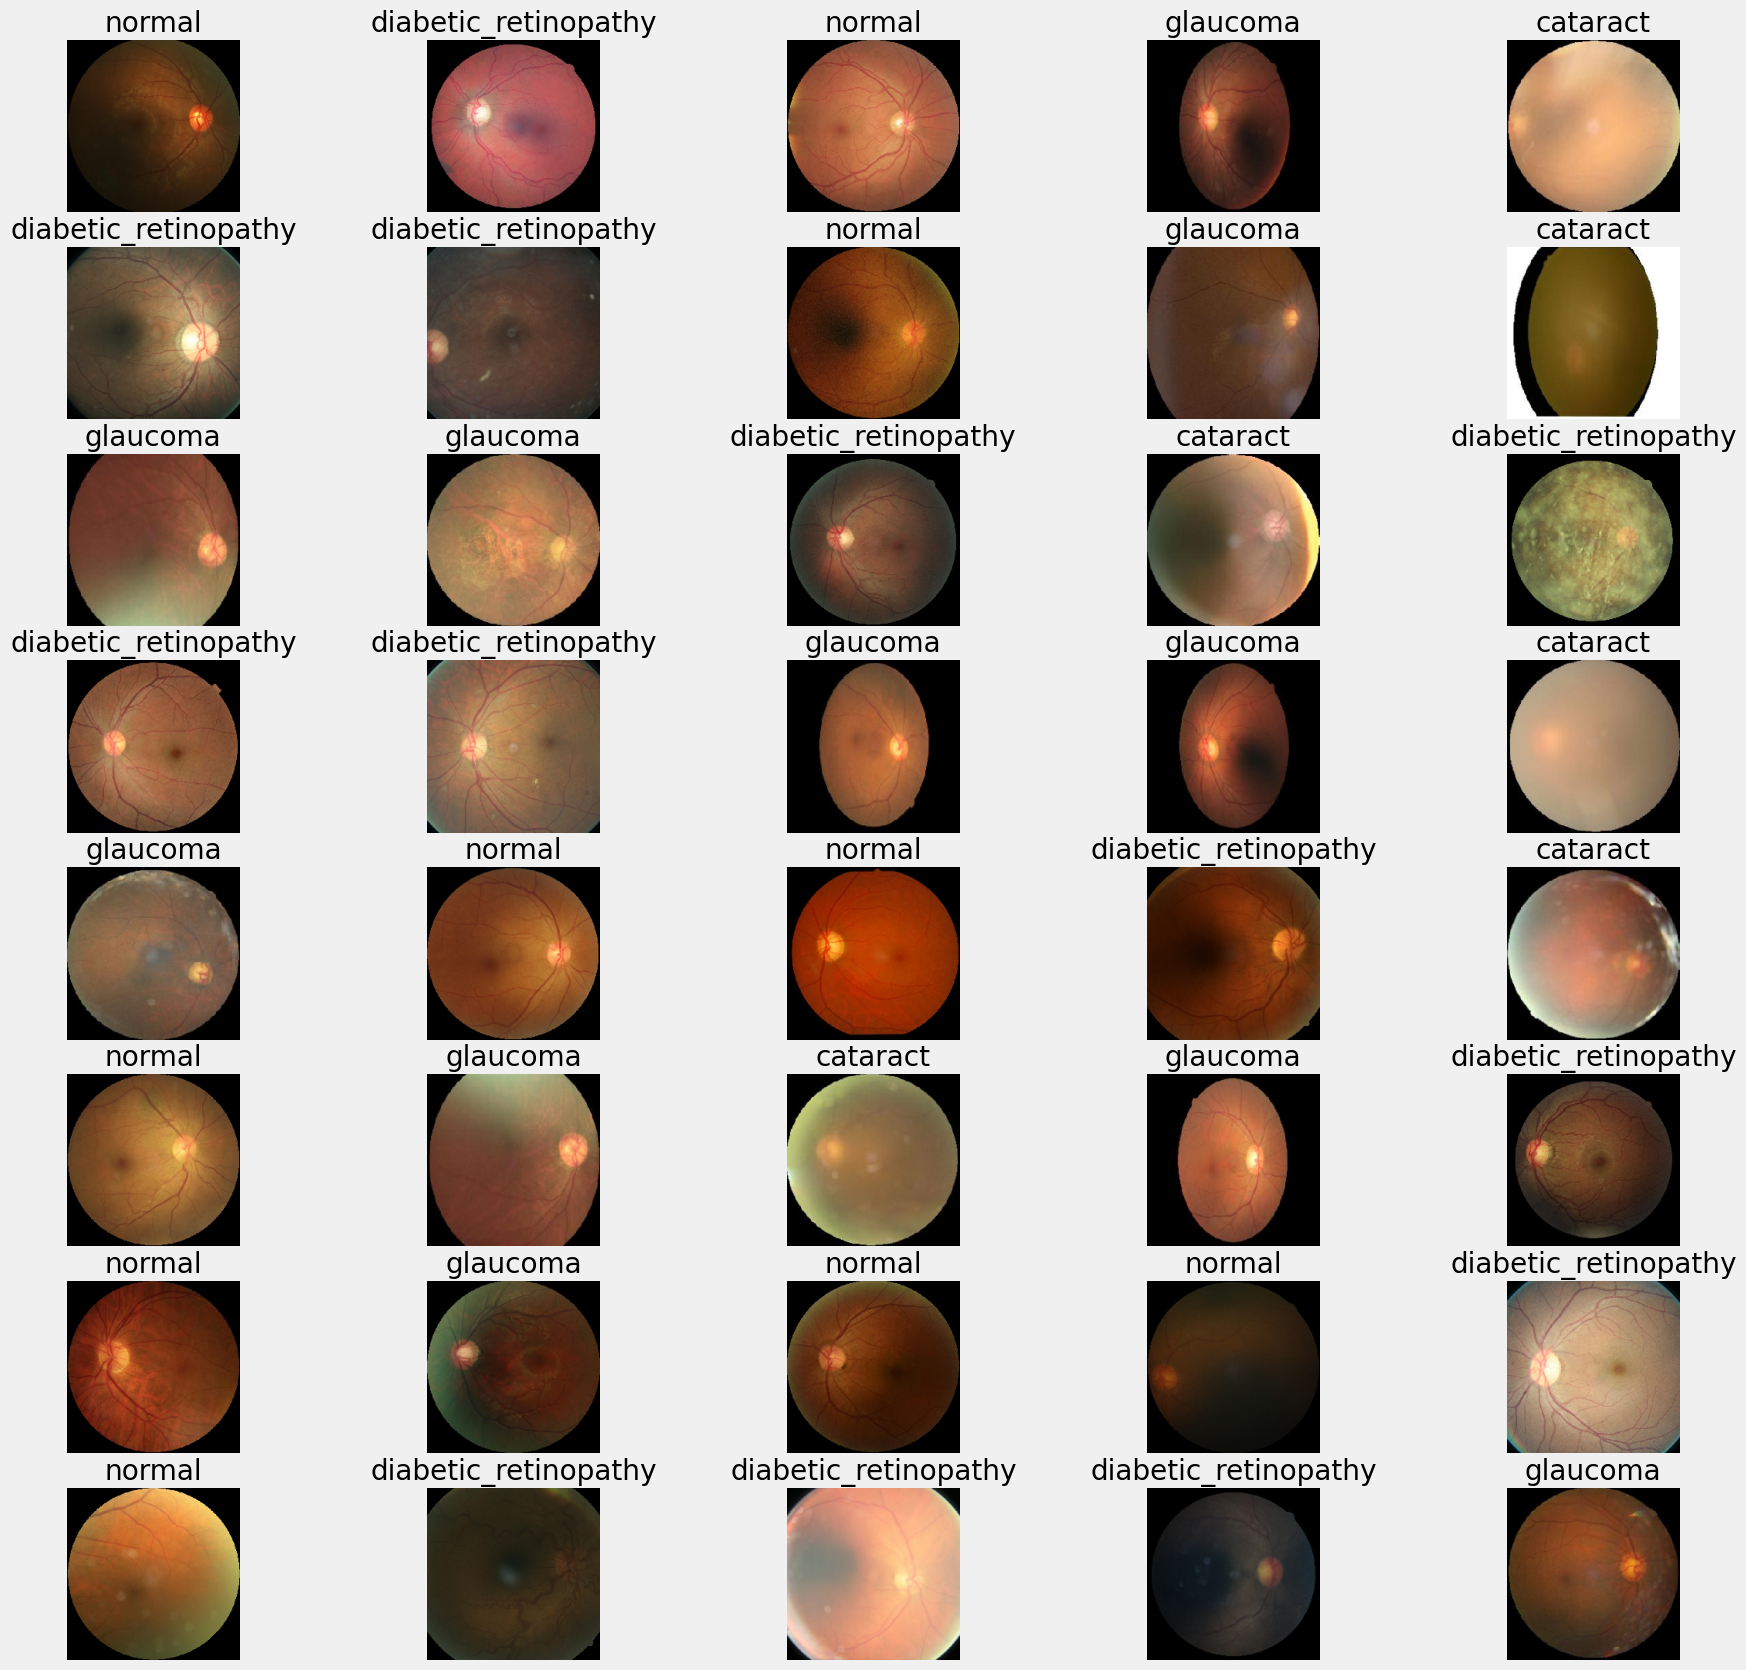

In [76]:

max_images = 40  
plt.figure(figsize=(20,20))
for X_batch, y_batch in train:
    for i in range(min(max_images, len(X_batch))):
        plt.subplot(8, 5, i + 1)  
        plt.imshow(X_batch[i])
        plt.title(classes[np.where(y_batch[i] == 1)[0][0]])
        plt.axis('off')
    plt.show()
    break


# Visualizing Validation Set Samples

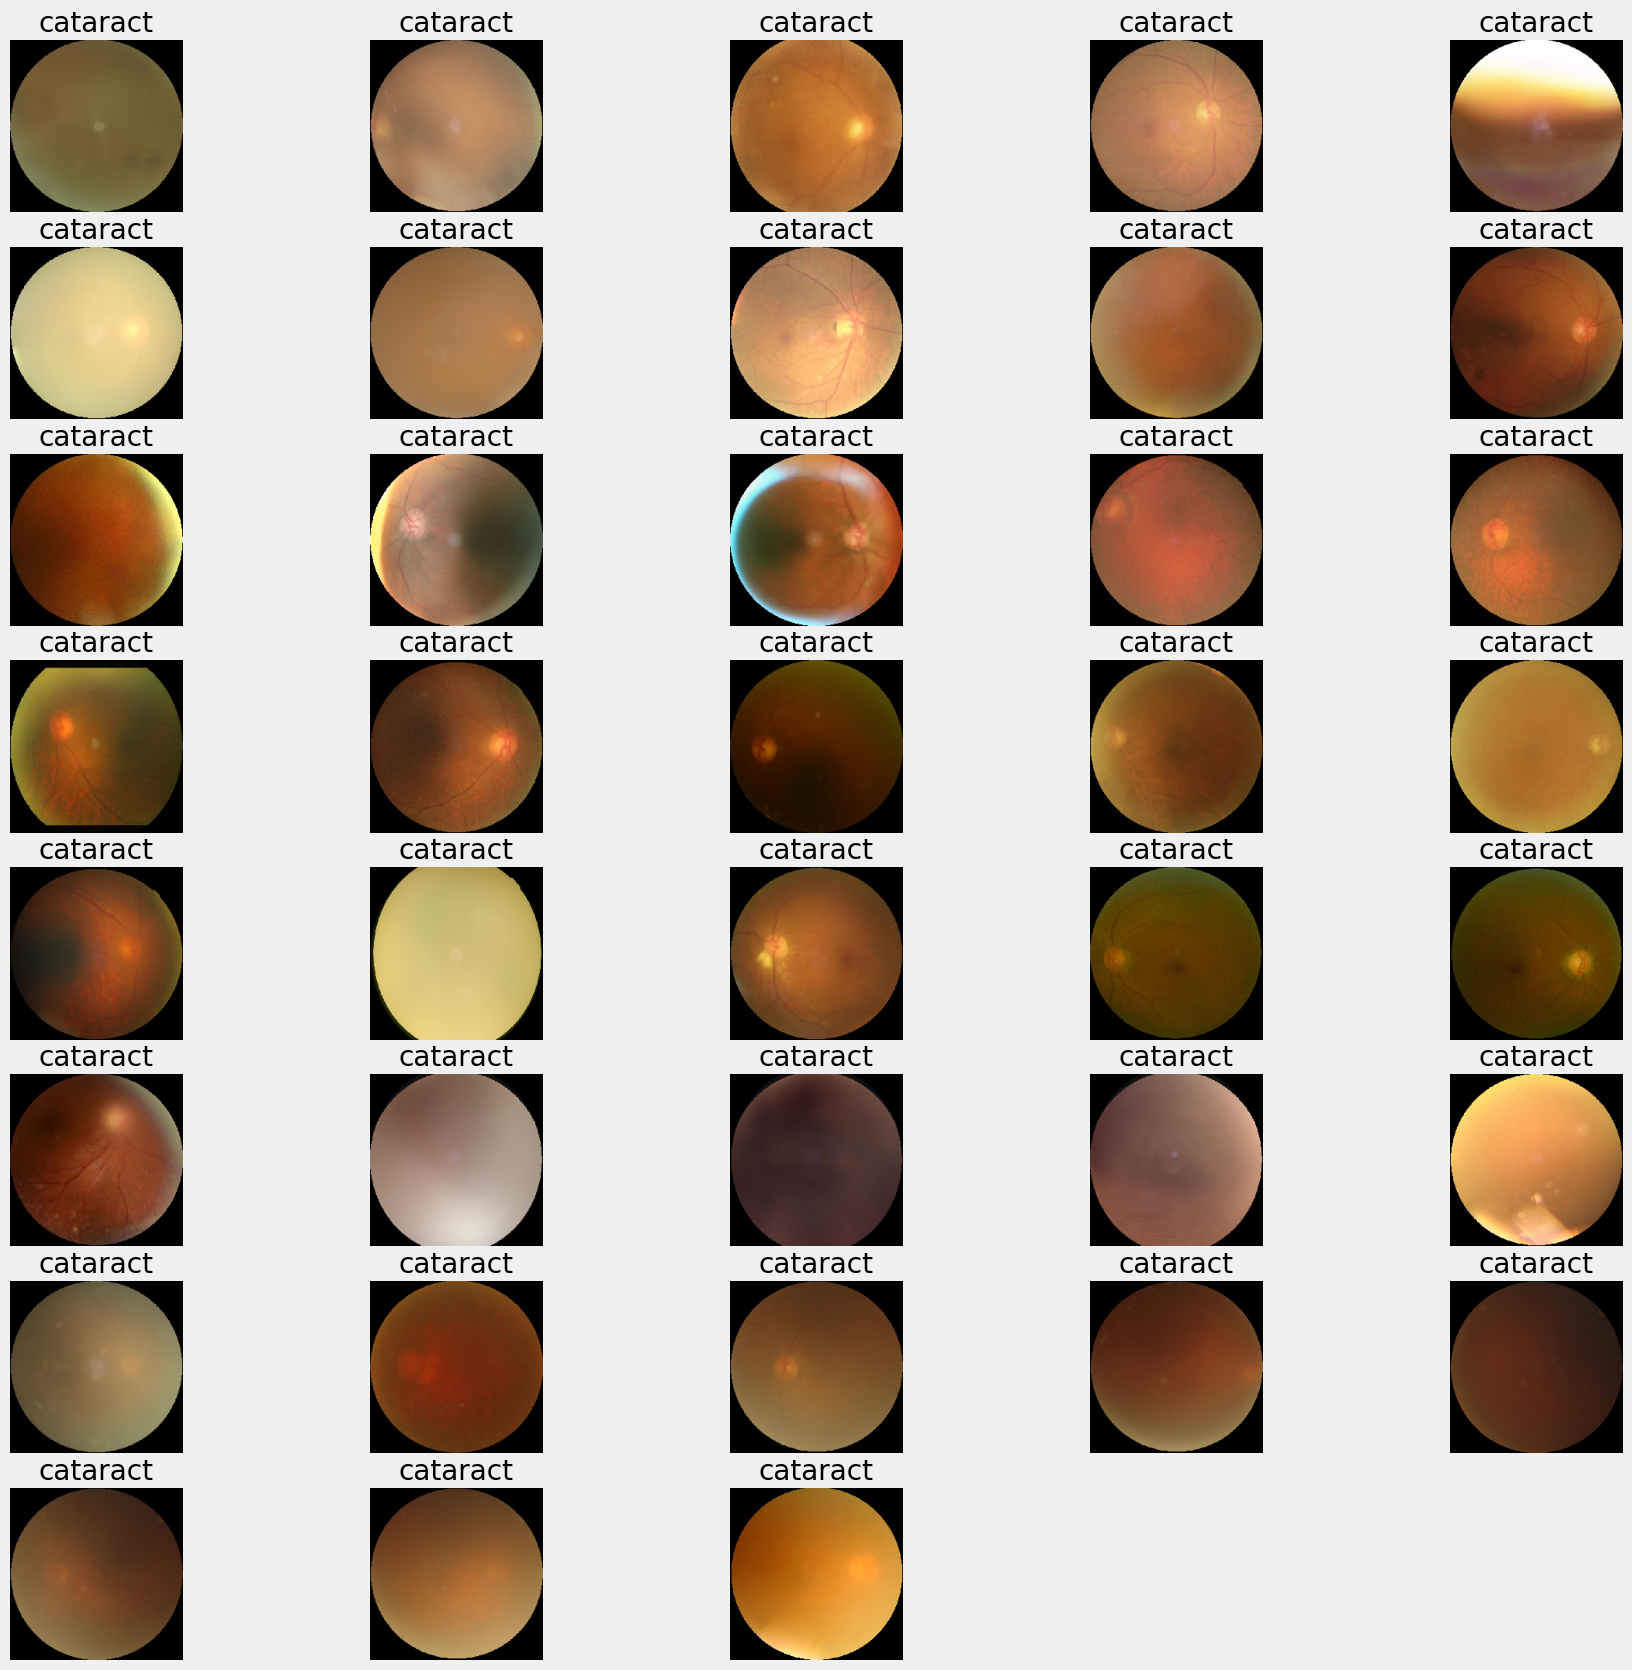

In [77]:

max_images = 38 
plt.figure(figsize=(20,20))
for X_batch, y_batch in validation:
    # Create a grid of images based on the maximum number
    for i in range(min(max_images, len(X_batch))):  #
        plt.subplot(8, 5, i + 1)  # Adjust the grid size as needed
        plt.imshow(X_batch[i])
        plt.title(classes[np.where(y_batch[i] == 1)[0][0]])  # When y is categorical
        plt.axis('off')  # Turn off grid lines
    plt.show()  # Show the plot
    break  


# Resnet50 Model

## 1. Define ResNet50 base model

In [78]:
input_shape = (224, 224, 3)
input_layer=tf.keras.Input(input_shape)
resnet50_base_model=ResNet50(include_top=False,weights='imagenet',input_tensor=input_layer)
# Freeze the base model layers
#resnet50_base_model.trainable = False

resnet50_base_model.trainable = False

##  2. Build ResNet50 Model Architecture

In [79]:
resnet50_model = tf.keras.models.Sequential([
        resnet50_base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(38, activation='softmax')  # Adjust output units
    ])
resnet50_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [80]:
resnet50_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 3. Compile the model

In [81]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

resnet50_model.compile(loss="categorical_crossentropy", optimizer= optimizer, metrics=["accuracy",'precision','recall'])

## 4. Set callbacks

In [82]:
#callbacks
early_stopping=EarlyStopping(monitor='val_loss',patience=8,verbose=1, restore_best_weights=True)
checkpoints=ModelCheckpoint('resnet50.keras', monitor='val_loss', save_best_only=True,verbose=1)
reduceonplateau=ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=0.000001)
callback=[early_stopping,reduceonplateau,checkpoints]

## 5. Train ResNet50 model

In [83]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Input shape for images
input_shape = (224, 224, 3)

# Define input layer
input_layer = tf.keras.Input(shape=input_shape)

# Load ResNet50 base model
resnet50_base_model = ResNet50(include_top=False, weights='imagenet', input_tensor=input_layer)

# Freeze the base model layers
resnet50_base_model.trainable = False

# Build the sequential model
resnet50_model = tf.keras.models.Sequential([
    resnet50_base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(4, activation='softmax')  # Adjusted output units for 3 classes
])

# Model summary
resnet50_model.summary()

# Define optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Compile the model
resnet50_model.compile(
    loss="categorical_crossentropy", 
    optimizer=optimizer, 
    metrics=["accuracy", tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# Define callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=8, verbose=1, restore_best_weights=True)
checkpoints = ModelCheckpoint('resnet50.keras', monitor='val_loss', save_best_only=True, verbose=1)
reduce_on_plateau = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=0.000001)

callbacks = [early_stopping, reduce_on_plateau, checkpoints]

# Train the model
resnet50_history = resnet50_model.fit(
    train,
    epochs=20,
    validation_data=validation,
    callbacks=callbacks,
    batch_size=64
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2616 - loss: 1.6520 - precision: 0.2754 - recall: 0.0786
Epoch 1: val_loss improved from inf to 1.40875, saving model to resnet50.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step - accuracy: 0.2613 - loss: 1.6464 - precision: 0.2747 - recall: 0.0767 - val_accuracy: 0.2384 - val_loss: 1.4087 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 967ms/step - accuracy: 0.2630 - loss: 1.4421 - precision: 0.3266 - recall: 0.0235
Epoch 2: val_loss improved from 1.40875 to 1.36361, saving model to resnet50.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.2641 - loss: 1.4417 - precision: 0.3286 - recall: 0.0234 - val_accuracy: 0.2477 - val_loss: 1.3636 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 962ms/step - accuracy: 0.2812 - loss: 1.4161 - precision: 0.2526 - recall: 0.0056
Epoch 3: val_l

### Setting Evaluation and plotting metrics functions

In [109]:
def evaluate_model (model,train_generator,test_generator):
    model_evaluate_train=model.evaluate(train_generator)
    print("Loss  ",model_evaluate_train[0])
    print("Accuracy  ",model_evaluate_train[1])
    print("precision  ",model_evaluate_train[2])
    print("Recall  ",model_evaluate_train[3])
    
    
    model_evaluate_test=model.evaluate(test_generator)
    print("Loss  ",model_evaluate_test[0])
    print("Accuracy  ",model_evaluate_test[1])
    print("precision  ",model_evaluate_test[2])
    print("Recall  ",model_evaluate_test[3])
    
    return np.round(model_evaluate_train[0],2),np.round(model_evaluate_test[0],2),np.round(model_evaluate_train[1],2),np.round(model_evaluate_test[1],2),np.round(model_evaluate_train[2],2),np.round(model_evaluate_test[2],2),np.round(model_evaluate_train[3],2),np.round(model_evaluate_test[3],2)

In [112]:
Final_Report=[]

In [86]:

def plot_training_history(history, metrics, title="Training and Validation Metrics"):
    # Set up the plot grid
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(title, fontsize=16)

    
    for ax, metric in zip(axs.flat, metrics):
        ax.plot(history.history[metric], label=f'Training {metric.capitalize()}')
        ax.plot(history.history[f'val_{metric}'], label=f'Validation {metric.capitalize()}')
        ax.set_xlabel('Epochs')
        ax.set_ylabel(metric.capitalize())
        ax.set_title(f'Training and Validation {metric.capitalize()}')
        ax.legend()

   
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


metrics = ['accuracy', 'loss', 'recall', 'precision']



## 6. Evaluate the model

In [87]:
Final_Report.append(evaluate_model(resnet50_model,train,test))

17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.4944 - loss: 1.2715 - precision: 0.5845 - recall: 0.0241
Loss   1.2749390602111816
Accuracy   0.47870370745658875
precision   0.6219512224197388
Recall   0.02361111156642437
7/7 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.4588 - loss: 1.2880 - precision: 0.5055 - recall: 0.0211
Loss   1.2819703817367554
Accuracy   0.4591715931892395
precision   0.6000000238418579
Recall   0.024852070957422256


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score

# Step 1: Predict class probabilities
y_pred_prob = resnet50_model.predict(test)

# Step 2: Convert to class labels
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

# Step 3: Accuracy
acc = accuracy_score(y_true, y_pred)

# Step 4: Precision & Recall (weighted for multi-class)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')

print("=== ResNet50 Evaluation ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

# Step 5: Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

# Step 6: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - ResNet50")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## 7.  Plotting Training and Validation Metrics

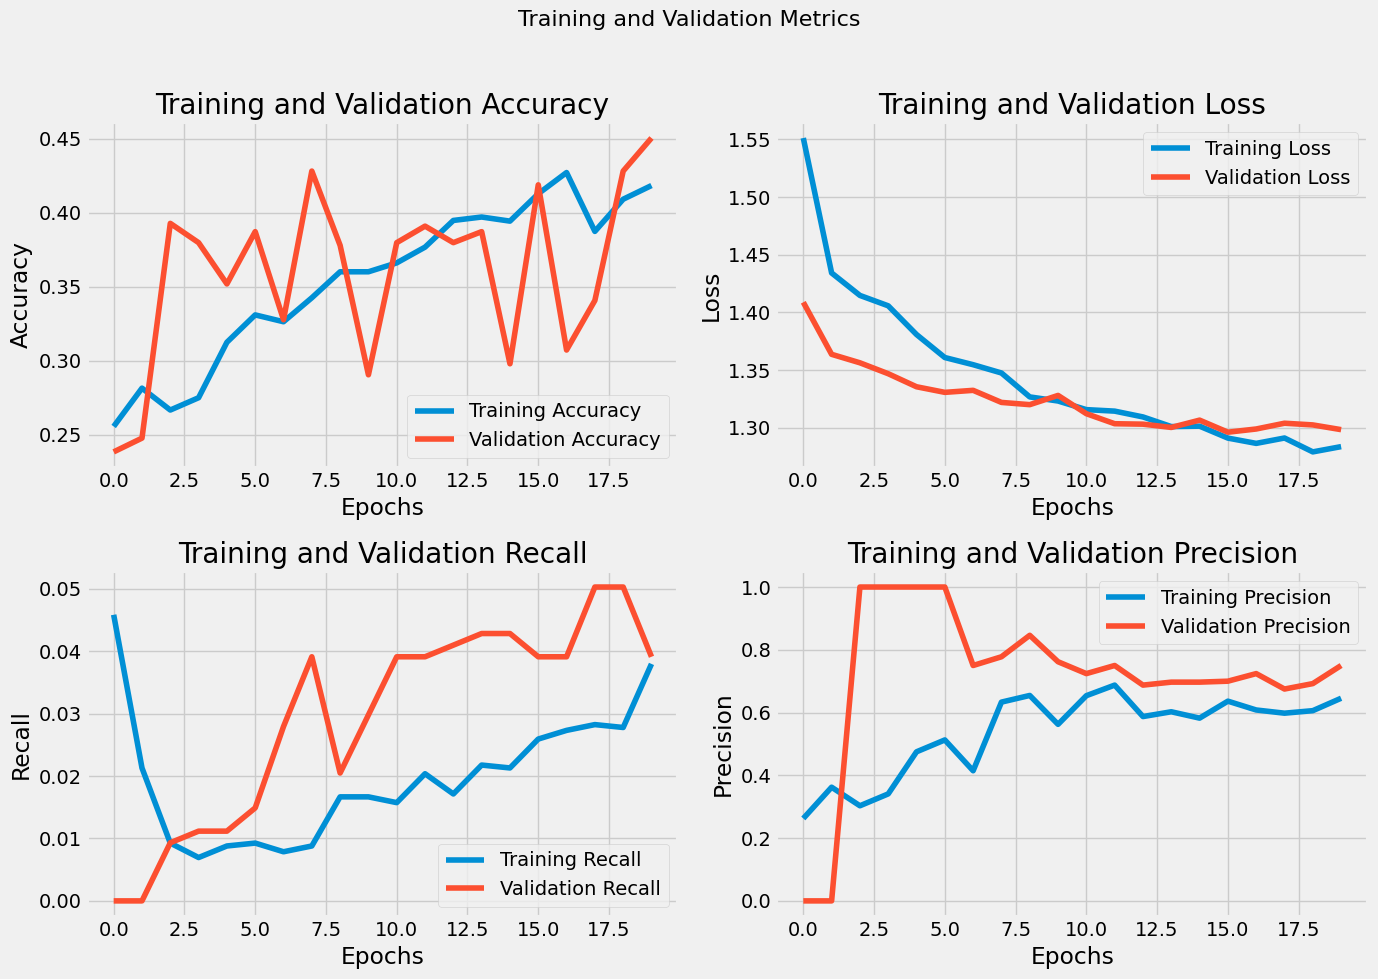

In [113]:
plot_training_history(resnet50_history, metrics)

# Now VGG16

## 1. Define the base model

In [22]:
vgg16_base_model=VGG16(include_top=False,weights='imagenet',input_shape=(224,224,3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [23]:
vgg16_base_model.trainable = False

## 2. Build VGG16 Model Architechture

In [24]:
#Transfer Learning Model
inputs=tf.keras.Input(shape=(224,224,3))
x=vgg16_base_model(inputs)
x=tf.keras.layers.GlobalAveragePooling2D()(x)
x= tf.keras.layers.BatchNormalization()(x)
x= tf.keras.layers.Dropout(0.2)(x)
outputs=tf.keras.layers.Dense(38, activation="softmax")(x)
vgg16_model = tf.keras.Model(inputs=inputs, outputs=outputs)
vgg16_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        19,494 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,736,230 (56.21 MB)

 Trainable params: 20,518 (80.15 KB)

 Non-trainable params: 14,715,712 (56.14 MB)

## 3. Compile The Model

In [25]:
vgg16_model.compile(loss="categorical_crossentropy", optimizer= 'adam', metrics=["accuracy",'precision','recall'])

## 4. Set Callbacks

In [26]:
early_stopping_vgg=EarlyStopping(monitor='val_loss',patience=8,verbose=2, restore_best_weights=True)
checkpoints_vgg=ModelCheckpoint('vgg16.keras', monitor='val_loss', save_best_only=True,verbose=2)
reduceonplateau_vgg=ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.000001)
callback_vgg=[early_stopping_vgg,reduceonplateau_vgg,checkpoints_vgg]

## 5. Train VGG16 Model

In [27]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Load VGG16 base model
vgg16_base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
vgg16_base_model.trainable = False

# Define model structure
inputs = tf.keras.Input(shape=(224, 224, 3))
x = vgg16_base_model(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax")(x)  # Adjusted to 3 classes
vgg16_model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Model summary
vgg16_model.summary()

# Compile the model
vgg16_model.compile(
    loss="categorical_crossentropy", 
    optimizer='adam', 
    metrics=["accuracy", tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# Callbacks
early_stopping_vgg = EarlyStopping(monitor='val_loss', patience=8, verbose=2, restore_best_weights=True)
checkpoints_vgg = ModelCheckpoint('vgg16.keras', monitor='val_loss', save_best_only=True, verbose=2)
reduce_on_plateau_vgg = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.000001)
callback_vgg = [early_stopping_vgg, reduce_on_plateau_vgg, checkpoints_vgg]

# Train the model
vgg16_history = vgg16_model.fit(
    train,
    epochs=35,
    validation_data=validation,
    callbacks=callback_vgg
)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,718,788 (56.15 MB)

 Trainable params: 3,076 (12.02 KB)

 Non-trainable params: 14,715,712 (56.14 MB)

Epoch 1/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2947 - loss: 1.5942 - precision_1: 0.3243 - recall_1: 0.1358
Epoch 1: val_loss improved from inf to 1.41080, saving model to vgg16.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 74s 3s/step - accuracy: 0.3006 - loss: 1.5801 - precision_1: 0.3334 - recall_1: 0.1399 - val_accuracy: 0.3873 - val_loss: 1.4108 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 956ms/step - accuracy: 0.6248 - loss: 0.8854 - precision_1: 0.7254 - recall_1: 0.4605
Epoch 2: val_loss improved from 1.41080 to 1.37157, saving model to vgg16.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.6268 - loss: 0.8822 - precision_1: 0.7270 - recall_1: 0.4641 - val_accuracy: 0.2384 - val_loss: 1.3716 - val_precision_1: 0.3333 - val_recall_1: 0.0037 - learning_rate: 0.0010
Epoch 3/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.7323 - loss: 0.6866 - precision_1: 0.7986 - recall_1: 0.6392


## 6. Evaluate the model

In [28]:
Final_Report.append(evaluate_model(vgg16_model,train,test))

17/17 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8846 - loss: 0.3432 - precision_1: 0.9105 - recall_1: 0.8546
Loss   0.3370606005191803
Accuracy   0.887499988079071
precision   0.914370059967041
Recall   0.8601852059364319
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.8660 - loss: 0.3791 - precision_1: 0.8920 - recall_1: 0.8356
Loss   0.3827073574066162
Accuracy   0.8662722110748291
precision   0.8919948935508728
Recall   0.8307692408561707


## 7. Plotting Training and Validation Metrics

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,718,788 (56.15 MB)

 Trainable params: 3,076 (12.02 KB)

 Non-trainable params: 14,715,712 (56.14 MB)

Epoch 1/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4119 - loss: 1.3405 - precision: 0.5013 - recall: 0.2556   
Epoch 1: val_loss improved from inf to 1.39577, saving model to vgg16.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.4163 - loss: 1.3308 - precision: 0.5072 - recall: 0.2601 - val_accuracy: 0.3166 - val_loss: 1.3958 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6213 - loss: 0.8500 - precision: 0.7249 - recall: 0.5229
Epoch 2: val_loss did not improve from 1.39577
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6232 - loss: 0.8473 - precision: 0.7264 - recall: 0.5246 - val_accuracy: 0.2644 - val_loss: 1.4390 - val_precision: 0.8182 - val_recall: 0.0168 - learning_rate: 0.0010
Epoch 3/35
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7400 - loss: 0.6440 - precision: 0.8158 - recall: 0.6539
Epoch 3: val_loss did not improve from 1.39577
17/17 ━━━━━━━━━━━

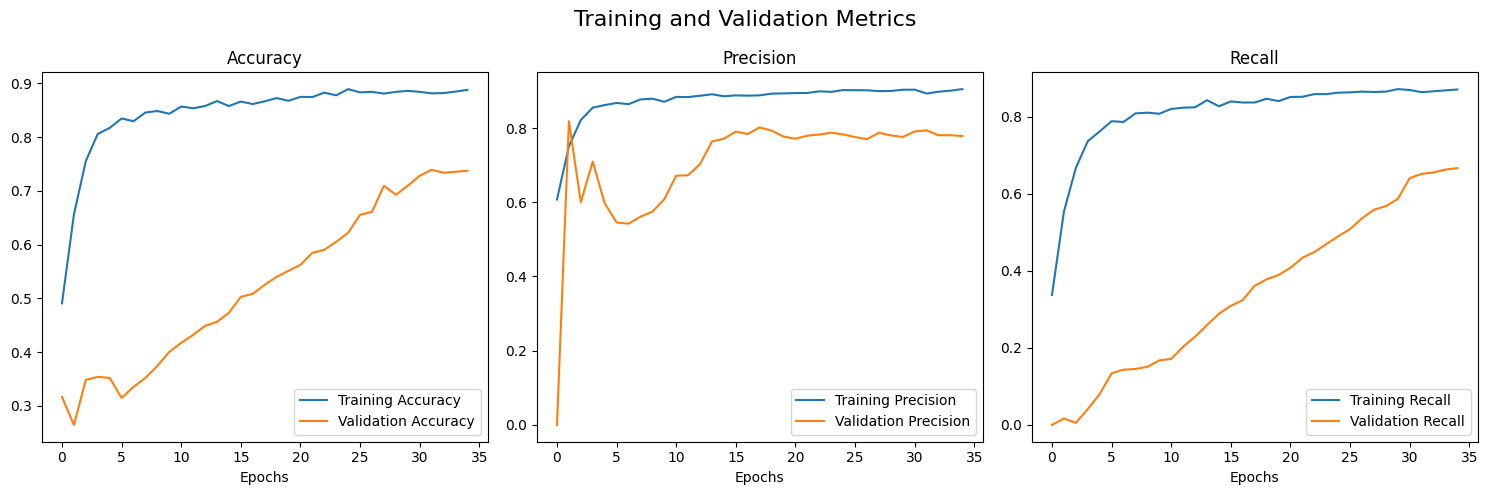

In [29]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

# Load VGG16 base model
vgg16_base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
vgg16_base_model.trainable = False

# Define model structure
inputs = tf.keras.Input(shape=(224, 224, 3))
x = vgg16_base_model(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax")(x)  # Adjusted for 3 classes
vgg16_model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Model summary
vgg16_model.summary()

# Compile the model with TensorFlow metric objects
vgg16_model.compile(
    loss="categorical_crossentropy", 
    optimizer='adam', 
    metrics=["accuracy", tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Define callbacks
early_stopping_vgg = EarlyStopping(monitor='val_loss', patience=8, verbose=2, restore_best_weights=True)
checkpoints_vgg = ModelCheckpoint('vgg16.keras', monitor='val_loss', save_best_only=True, verbose=2)
reduce_on_plateau_vgg = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.000001)
callback_vgg = [early_stopping_vgg, reduce_on_plateau_vgg, checkpoints_vgg]

# Train the model
vgg16_history = vgg16_model.fit(
    train,
    epochs=35,
    validation_data=validation,
    callbacks=callback_vgg,
    batch_size=64  # Specify batch size if necessary
)

# Function to plot training history
def plot_training_history(history, metrics, title="Training and Validation Metrics"):
    fig, axs = plt.subplots(1, len(metrics), figsize=(15, 5))
    fig.suptitle(title, fontsize=16)

    for ax, metric in zip(axs.flat, metrics):
        if metric in history.history:  # Check if metric exists in history
            ax.plot(history.history[metric], label=f'Training {metric.capitalize()}')
            ax.plot(history.history[f'val_{metric}'], label=f'Validation {metric.capitalize()}')
            ax.set_xlabel('Epochs')
            ax.set_title(metric.capitalize())
            ax.legend()
        else:
            print(f"Metric '{metric}' not found in history.")
    plt.tight_layout()
    plt.show()

# Define the metrics to plot
metrics_to_plot = ['accuracy', 'precision', 'recall']

# Plot training history
plot_training_history(vgg16_history, metrics_to_plot)


In [30]:
Final_Report

[(np.float64(1.27),
  np.float64(1.28),
  np.float64(0.5),
  np.float64(0.46),
  np.float64(0.62),
  np.float64(0.68),
  np.float64(0.02),
  np.float64(0.02)),
 (np.float64(0.34),
  np.float64(0.38),
  np.float64(0.89),
  np.float64(0.87),
  np.float64(0.91),
  np.float64(0.89),
  np.float64(0.86),
  np.float64(0.83))]

In [31]:
models_name=['ResNet50','VGG16']
Model_accuracy=pd.DataFrame(Final_Report,index=models_name,columns=['Train Loss','Test Loss','Train Accuracy','Test Accuracy','Train precision','Test precision','Train Recall','Test Recall'])


In [34]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Dense, Flatten, Concatenate, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Image input size
IMG_SIZE = (224, 224, 3)

# Define a single shared input layer
input_layer = Input(shape=IMG_SIZE, name="shared_input")

# Load pre-trained models with shared input
vgg16_base = VGG16(weights="imagenet", include_top=False, input_tensor=input_layer)
resnet50_base = ResNet50(weights="imagenet", include_top=False, input_tensor=input_layer)

# Freeze pre-trained layers
for model in [vgg16_base, resnet50_base]:
    for layer in model.layers:
        layer.trainable = False  # Freeze pre-trained weights

# Extract feature maps using Global Average Pooling (reduces parameters)
vgg16_features = GlobalAveragePooling2D(name="vgg16_pool")(vgg16_base.output)
resnet50_features = GlobalAveragePooling2D(name="resnet50_pool")(resnet50_base.output)

# Merge feature vectors
merged = Concatenate(name="merged_features")([vgg16_features, resnet50_features])

# Fully connected layers
fc = Dense(512, activation="relu", name="fc1")(merged)
fc = Dropout(0.5, name="dropout1")(fc)
fc = Dense(256, activation="relu", name="fc2")(fc)
fc = Dropout(0.5, name="dropout2")(fc)
output = Dense(4, activation="softmax", name="output_layer")(fc)  # Adjust for 3 classes

# Define the merged model
merged_model = Model(inputs=input_layer, outputs=output)

# Compile the model
merged_model.compile(optimizer=Adam(learning_rate=0.0001), loss="categorical_crossentropy", metrics=["accuracy"])

# Summary
merged_model.summary()

# ---------------------- DATA LOADING ---------------------- #
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=30, horizontal_flip=True, validation_split=0.2)

# Load dataset from directory (modify path accordingly)
train_generator = train_datagen.flow_from_directory(
    "/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/train",  # Change to your dataset path
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

val_generator = train_datagen.flow_from_directory(
    "/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/val",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

# ---------------------- TRAIN MODEL FOR 30 EPOCHS ---------------------- #
history = merged_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=35
)


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ shared_input        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ shared_input[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 39,745,988 (151.62 MB)

 Trainable params: 1,443,588 (5.51 MB)

 Non-trainable params: 38,302,400 (146.11 MB)

Found 2160 images belonging to 4 classes.
Found 134 images belonging to 4 classes.
Epoch 1/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 73s 791ms/step - accuracy: 0.2574 - loss: 1.6650 - val_accuracy: 0.4328 - val_loss: 1.3365
Epoch 2/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 37s 539ms/step - accuracy: 0.2911 - loss: 1.4281 - val_accuracy: 0.5746 - val_loss: 1.2843
Epoch 3/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 37s 537ms/step - accuracy: 0.3834 - loss: 1.3123 - val_accuracy: 0.6119 - val_loss: 1.2275
Epoch 4/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 36s 520ms/step - accuracy: 0.4581 - loss: 1.2330 - val_accuracy: 0.5970 - val_loss: 1.1479
Epoch 5/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 36s 524ms/step - accuracy: 0.4916 - loss: 1.1576 - val_accuracy: 0.5746 - val_loss: 1.1017
Epoch 6/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 37s 545ms/step - accuracy: 0.4926 - loss: 1.1183 - val_accuracy: 0.6418 - val_loss: 1.0390
Epoch 7/35
68/68 ━━━━━━━━━━━━━━━━━━━━ 37s 544ms/step - accuracy: 0.5341 - loss: 1.0629 - val_accuracy: 0.6343 - val_loss: 1.0042
Epoch 8/35
68/

Found 845 images belonging to 4 classes.
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 266ms/step - accuracy: 0.7551 - loss: 0.6688

✅ Test Accuracy: 71.36%
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 404ms/step


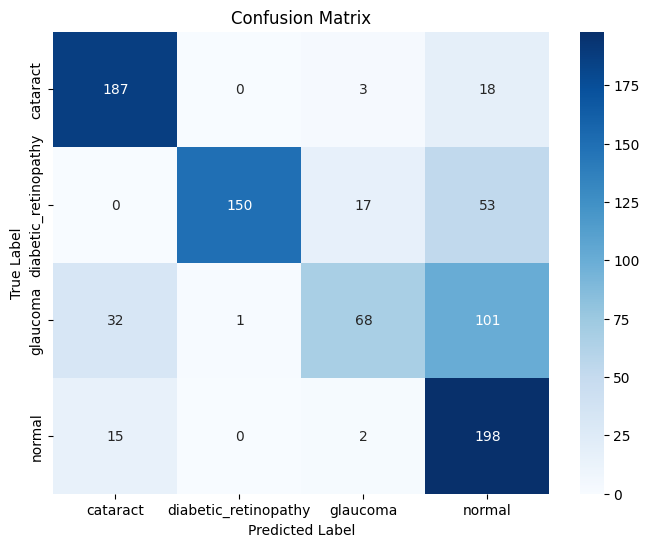


📌 Classification Report:

                      precision    recall  f1-score   support

            cataract       0.80      0.90      0.85       208
diabetic_retinopathy       0.99      0.68      0.81       220
            glaucoma       0.76      0.34      0.47       202
              normal       0.54      0.92      0.68       215

            accuracy                           0.71       845
           macro avg       0.77      0.71      0.70       845
        weighted avg       0.77      0.71      0.70       845



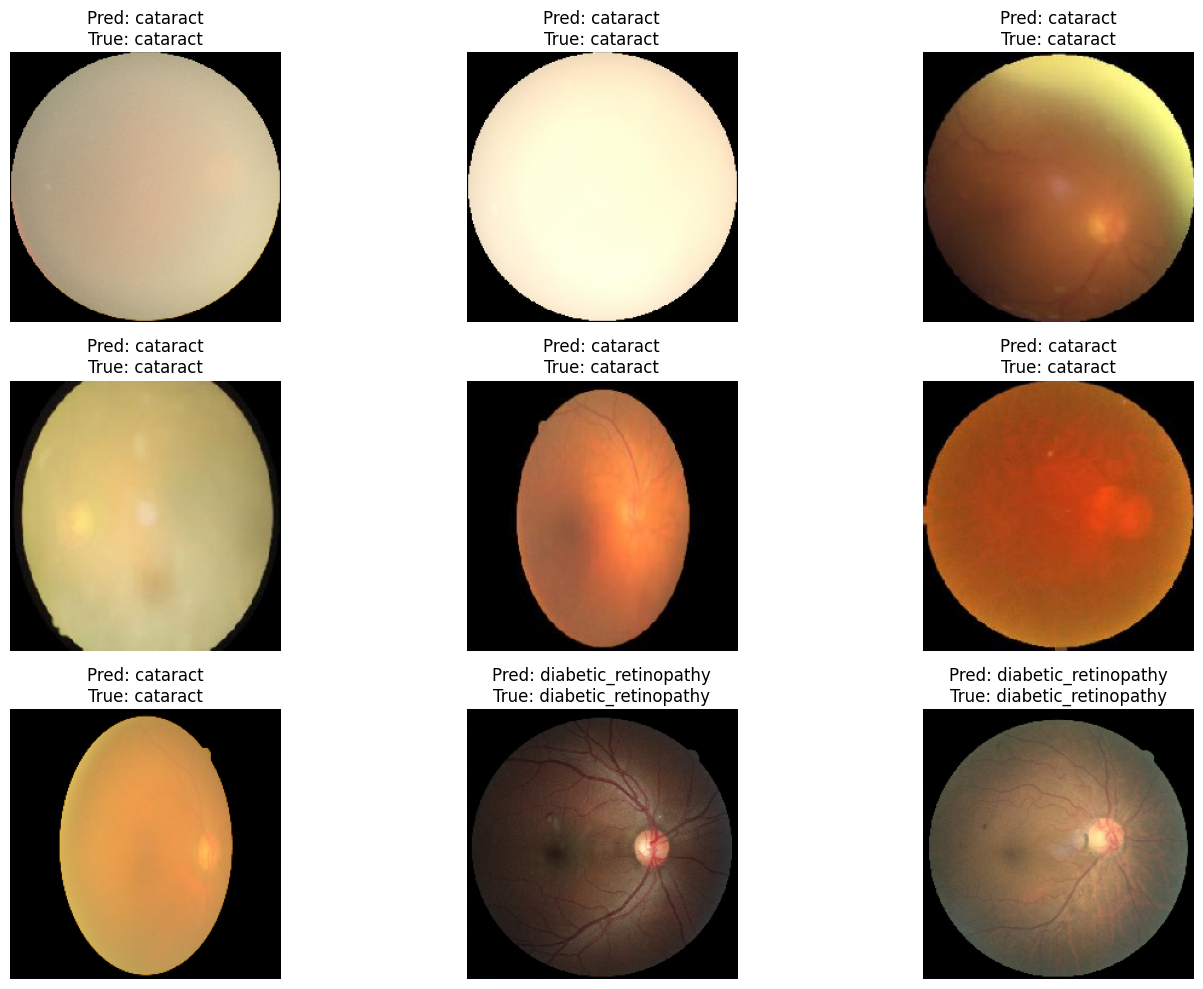

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve
)

# =========================
# TEST DATA
# =========================

test_datagen = ImageDataGenerator(rescale=1.0/255)

test_generator = test_datagen.flow_from_directory(
    "/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

# =========================
# MODEL EVALUATION
# =========================

test_loss, test_accuracy = merged_model.evaluate(test_generator)

print(f"\n✅ Test Accuracy: {test_accuracy * 100:.2f}%")

# =========================
# PREDICTION
# =========================

test_generator.reset()

y_pred = merged_model.predict(test_generator)

# Predicted class
y_pred_classes = np.argmax(y_pred, axis=1)

# True class
y_true = test_generator.classes

# Class labels
class_labels = list(test_generator.class_indices.keys())

# =========================
# 1. CONFUSION MATRIX
# =========================

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

# =========================
# 2. CLASSIFICATION REPORT
# =========================

print("\n📌 Classification Report:\n")

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=class_labels
))

# =========================
# 3. SAMPLE PREDICTIONS
# =========================

plt.figure(figsize=(15,10))

for i in range(9):

    image, label = test_generator[i]

    plt.subplot(3,3,i+1)

    plt.imshow(image[0])

    pred = merged_model.predict(
        np.expand_dims(image[0], axis=0),
        verbose=0
    )

    pred_class = class_labels[np.argmax(pred)]

    true_class = class_labels[np.argmax(label[0])]

    plt.title(f"Pred: {pred_class}\nTrue: {true_class}")

    plt.axis('off')

plt.tight_layout()

plt.show()

# =========================
# 4. ROC CURVE
# =========================
# Works for Binary Classification

if len(class_labels) == 2:

    y_pred_prob = y_pred[:,1]

    fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)

    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(7,5))

    plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')

    plt.plot([0,1], [0,1], linestyle='--')

    plt.title('ROC Curve')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

    plt.legend()

    plt.show()

# =========================
# 5. PRECISION-RECALL CURVE
# =========================

if len(class_labels) == 2:

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_pred_prob
    )

    plt.figure(figsize=(7,5))

    plt.plot(recall, precision)

    plt.title('Precision-Recall Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')

    plt.show()

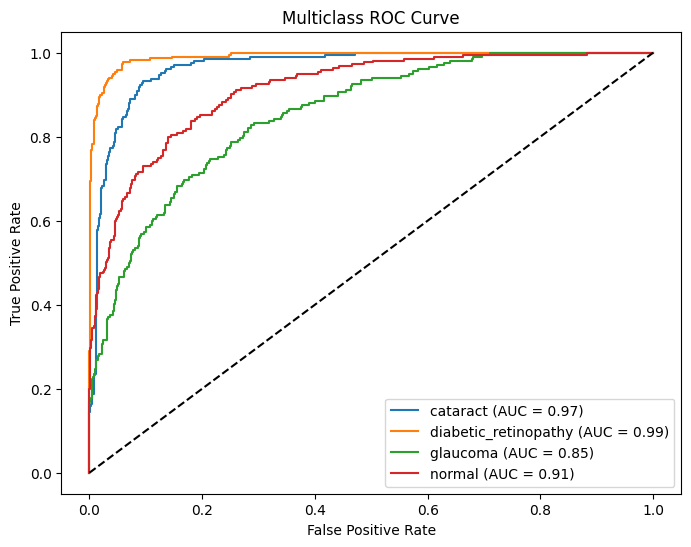

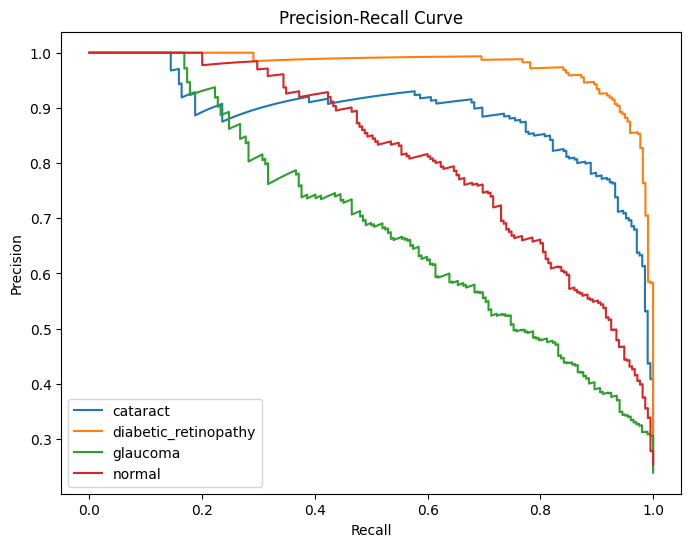

In [37]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve
from itertools import cycle

# =========================
# MULTICLASS ROC CURVE
# =========================

n_classes = len(class_labels)

# Convert labels to binary format
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# ROC Curve
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_pred[:, i]
    )

    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC Curve
plt.figure(figsize=(8,6))

for i in range(n_classes):

    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_labels[i]} (AUC = {roc_auc[i]:.2f})'
    )

plt.plot([0,1], [0,1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('Multiclass ROC Curve')

plt.legend()

plt.show()

# =========================
# PRECISION-RECALL CURVE
# =========================

precision = dict()
recall = dict()

for i in range(n_classes):

    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i],
        y_pred[:, i]
    )

# Plot Precision-Recall Curve
plt.figure(figsize=(8,6))

for i in range(n_classes):

    plt.plot(
        recall[i],
        precision[i],
        label=class_labels[i]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.show()

Test Accuracy : 0.7136094674556213
Test Precision: 0.7721201714273542


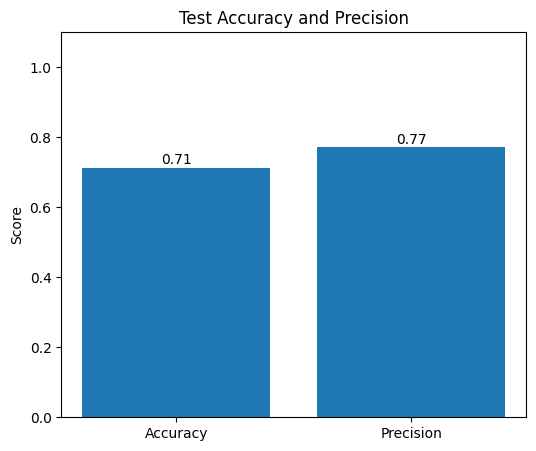

In [38]:
from sklearn.metrics import accuracy_score, precision_score

# =========================
# TEST ACCURACY & PRECISION
# =========================

test_acc = accuracy_score(y_true, y_pred_classes)

test_precision = precision_score(
    y_true,
    y_pred_classes,
    average='weighted'
)

print("Test Accuracy :", test_acc)
print("Test Precision:", test_precision)

# =========================
# BAR GRAPH
# =========================

metrics = ['Accuracy', 'Precision']
values = [test_acc, test_precision]

plt.figure(figsize=(6,5))

bars = plt.bar(metrics, values)

# Value labels
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.01,
        f'{yval:.2f}',
        ha='center'
    )

plt.ylim(0, 1.1)

plt.ylabel('Score')

plt.title('Test Accuracy and Precision')

plt.show()

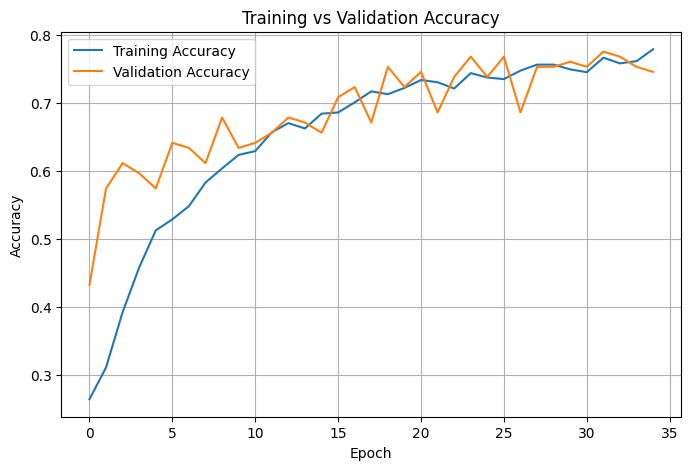

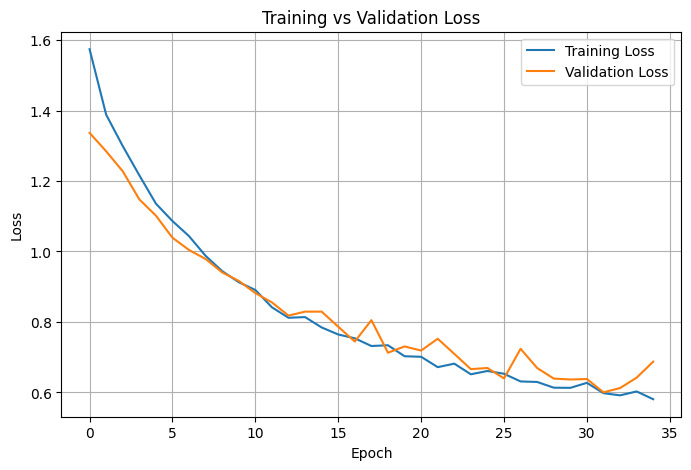

In [39]:
import matplotlib.pyplot as plt

# =========================
# TRAINING & VALIDATION ACCURACY
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training vs Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

plt.grid(True)

plt.show()

# =========================
# TRAINING & VALIDATION LOSS
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training vs Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.grid(True)

plt.show()

# =========================
# TRAINING & VALIDATION PRECISION
# =========================
# Works only if Precision metric used during model compile

if 'precision' in history.history:

    plt.figure(figsize=(8,5))

    plt.plot(
        history.history['precision'],
        label='Training Precision'
    )

    plt.plot(
        history.history['val_precision'],
        label='Validation Precision'
    )

    plt.title('Densenet:Training vs Validation Precision')

    plt.xlabel('Epoch')
    plt.ylabel('Precision')

    plt.legend()

    plt.grid(True)

    plt.show()

# The Final one is DenseNet121

## 1. Define the base model and Build model architecture

In [40]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam


densenet_base_model = DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
densenet_base_model.trainable = False  

# Build model architecture
inputs = layers.Input(shape=(224, 224, 3))
x = densenet_base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)  
outputs = layers.Dense(38, activation='softmax')(x)  


densenet_model = models.Model(inputs, outputs)

# Compile the model
densenet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)

# Summary to check layer details
densenet_model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 38)             │        38,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,076,454 (26.99 MB)

 Trainable params: 38,950 (152.15 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

## 2. Compile the model

In [ ]:
# Unfreeze last layers for fine-tuning
densenet_base_model.trainable = True
for layer in densenet_base_model.layers[:-20]:  
    layer.trainable = False

# Recompile before fine-tuning
densenet_model.compile(
    optimizer=Adam(learning_rate=0.001),  
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)


## 3. Set callbacks and Train The Model

Found 2697 images belonging to 4 classes.
Found 675 images belonging to 4 classes.


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,045,700 (26.88 MB)

 Trainable params: 6,148 (24.02 KB)

 Non-trainable params: 7,039,552 (26.85 MB)

Epoch 1/35
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5057 - loss: 1.1566 - precision: 0.5884 - recall: 0.3894
Epoch 1: val_loss improved from inf to 1.26130, saving model to densenet121.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.5081 - loss: 1.1510 - precision: 0.5909 - recall: 0.3924 - val_accuracy: 0.4874 - val_loss: 1.2613 - val_precision: 0.4940 - val_recall: 0.4237 - learning_rate: 0.0010
Epoch 2/35
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 993ms/step - accuracy: 0.7587 - loss: 0.6061 - precision: 0.8047 - recall: 0.7206
Epoch 2: val_loss improved from 1.26130 to 0.89932, saving model to densenet121.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.7589 - loss: 0.6056 - precision: 0.8048 - recall: 0.7207 - val_accuracy: 0.6237 - val_loss: 0.8993 - val_precision: 0.6347 - val_recall: 0.5585 - learning_rate: 0.0010
Epoch 3/35
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 979ms/step - accuracy: 0.7809 - loss: 0.5482 - precision: 0.8221 - recall: 0.7416
Epoch 3: val_loss improv

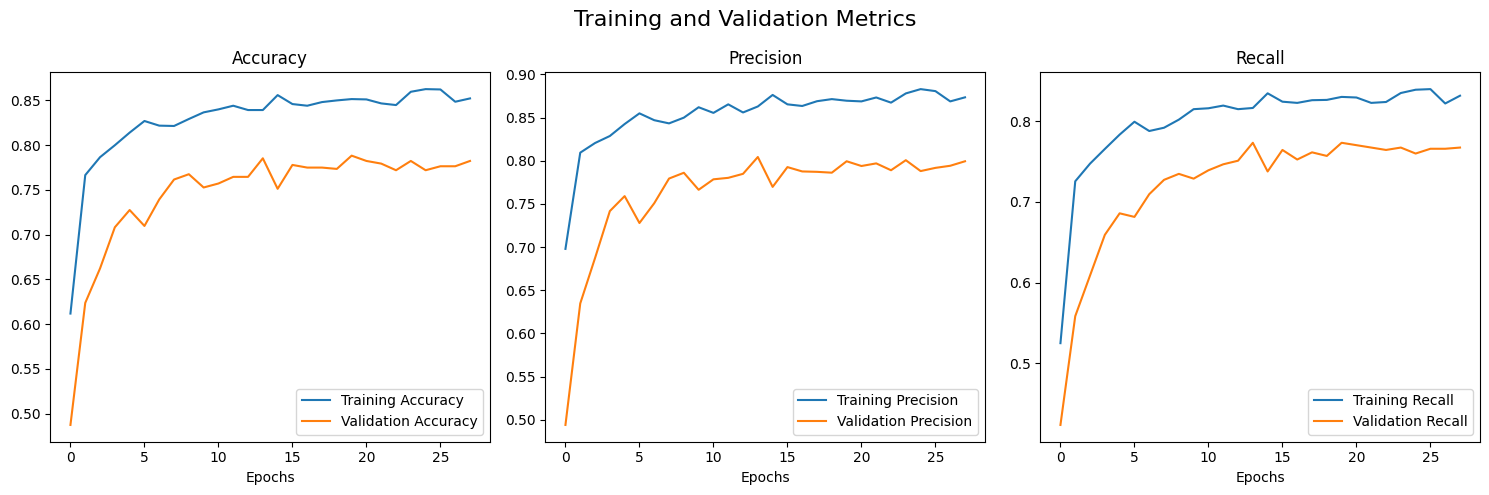

In [44]:


import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

# Define dataset directories (update these paths based on your dataset location)
train_dir = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/train'  # Update with your train dataset path
validation_dir = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/val'  # Update with your validation dataset path

# Load datasets using ImageDataGenerator
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

validation_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

train = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=64,
    class_mode='categorical'
)

validation = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(224, 224),
    batch_size=64,
    class_mode='categorical'
)

# Load DenseNet121 base model
densenet_base_model = DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
densenet_base_model.trainable = False

# Define model structure
inputs = tf.keras.Input(shape=(224, 224, 3))
x = densenet_base_model(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax")(x)  # Adjusted for 3 classes
densenet_model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Model summary
densenet_model.summary()

# Compile the model with TensorFlow metric objects
densenet_model.compile(
    loss="categorical_crossentropy", 
    optimizer='adam', 
    metrics=["accuracy", tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Define callbacks
early_stopping_densenet = EarlyStopping(monitor='val_loss', patience=8, verbose=2, restore_best_weights=True)
checkpoints_densenet = ModelCheckpoint('densenet121.keras', monitor='val_loss', save_best_only=True, verbose=2)
reduce_on_plateau_densenet = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.000001)
callback_densenet = [early_stopping_densenet, reduce_on_plateau_densenet, checkpoints_densenet]

# Train the model
densenet_history = densenet_model.fit(
    train,
    epochs=35,
    validation_data=validation,
    callbacks=callback_densenet
)

# Function to plot training history
def plot_training_history(history, metrics, title="Training and Validation Metrics"):
    fig, axs = plt.subplots(1, len(metrics), figsize=(15, 5))
    fig.suptitle(title, fontsize=16)

    for ax, metric in zip(axs.flat, metrics):
        if metric in history.history:  # Check if metric exists in history
            ax.plot(history.history[metric], label=f'Training {metric.capitalize()}')
            ax.plot(history.history[f'val_{metric}'], label=f'Validation {metric.capitalize()}')
            ax.set_xlabel('Epochs')
            ax.set_title(metric.capitalize())
            ax.legend()
        else:
            print(f"Metric '{metric}' not found in history.")
    plt.tight_layout()
    plt.show()

# Define the metrics to plot
metrics_to_plot = ['accuracy', 'precision', 'recall']

# Plot training history
plot_training_history(densenet_history, metrics_to_plot)


In [45]:
test_path = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/test'
test=test_datagen.flow_from_directory(test_path,
                                      target_size=(224,224)
                                      ,color_mode='rgb'
                                      ,class_mode='categorical',
                                      batch_size=128)
Final_Report.append(evaluate_model(densenet_model,train,test))

Found 845 images belonging to 4 classes.
43/43 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.8659 - loss: 0.3452 - precision: 0.8913 - recall: 0.8432
Loss   0.34597092866897583
Accuracy   0.8654060363769531
precision   0.8869395852088928
Recall   0.8435298204421997
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.8018 - loss: 0.5137 - precision: 0.8200 - recall: 0.7782
Loss   0.5445761680603027
Accuracy   0.7928994297981262
precision   0.8094059228897095
Recall   0.773964524269104


In [ ]:
# =========================
# TEST GENERATOR
# =========================

test_path = '/kaggle/input/datasets/rivaakter/eye-dataset/split_dataset/test'

test = test_datagen.flow_from_directory(
    test_path,
    target_size=(224,224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=128,
    shuffle=False
)

# =========================
# MODEL EVALUATION
# =========================

test_loss, test_accuracy = densenet_model.evaluate(test)

print(f"\n✅ Test Accuracy: {test_accuracy*100:.2f}%")

# =========================
# PREDICTION
# =========================

test.reset()

y_pred = densenet_model.predict(test)

y_pred_classes = np.argmax(y_pred, axis=1)

y_true = test.classes

class_labels = list(test.class_indices.keys())

# =========================
# CLASSIFICATION REPORT
# =========================

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=class_labels
))

## 4. Plot Training and Validation Metrics

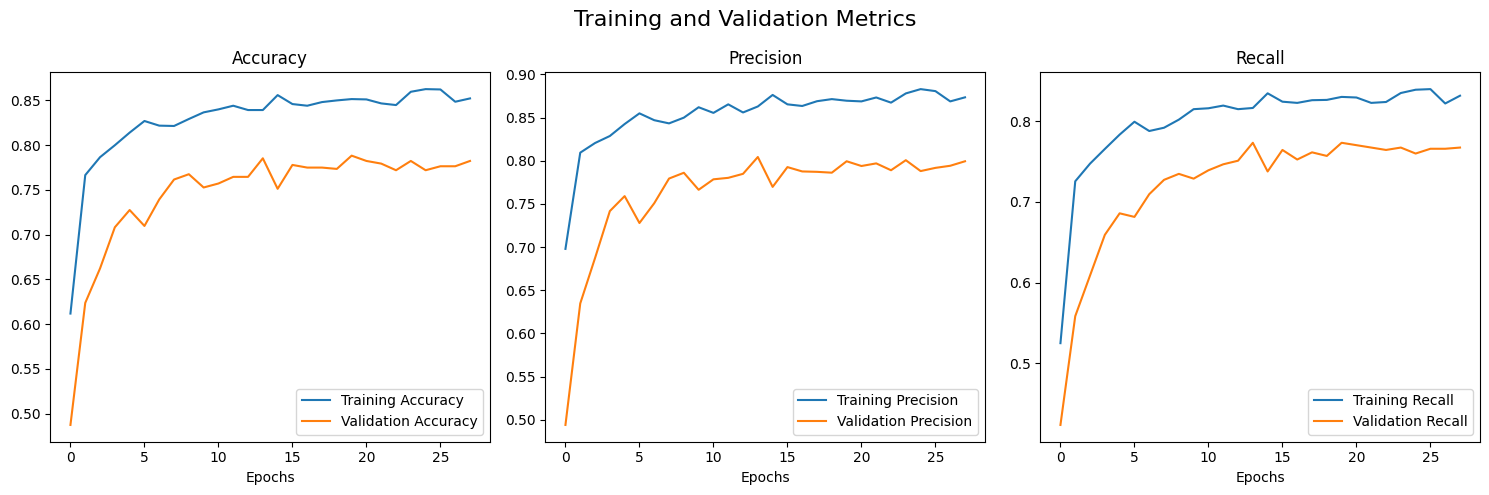

In [46]:
# Define the metrics to plot
metrics_to_plot = ['accuracy', 'precision', 'recall']

# Call the plot_training_history function with the correct variables
plot_training_history(densenet_history, metrics_to_plot)

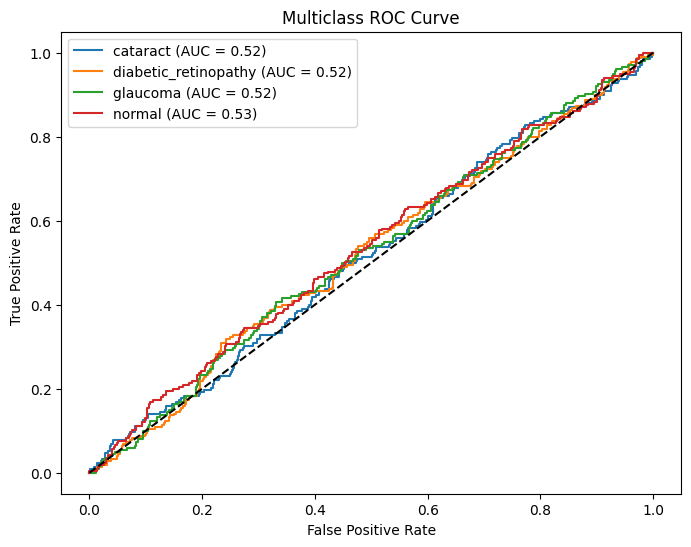

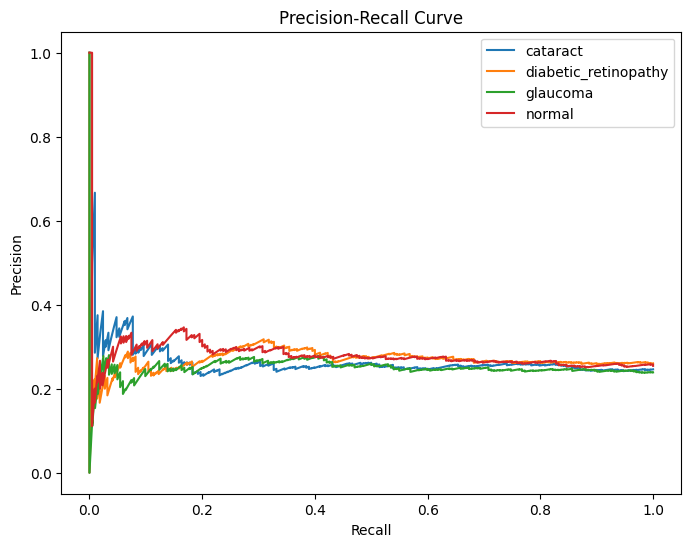

In [49]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve
from itertools import cycle

# =========================
# MULTICLASS ROC CURVE
# =========================

n_classes = len(class_labels)

# Convert labels to binary format
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# ROC Curve
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_pred[:, i]
    )

    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC Curve
plt.figure(figsize=(8,6))

for i in range(n_classes):

    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_labels[i]} (AUC = {roc_auc[i]:.2f})'
    )

plt.plot([0,1], [0,1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('Multiclass ROC Curve')

plt.legend()

plt.show()

# =========================
# PRECISION-RECALL CURVE
# =========================

precision = dict()
recall = dict()

for i in range(n_classes):

    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i],
        y_pred[:, i]
    )

# Plot Precision-Recall Curve
plt.figure(figsize=(8,6))

for i in range(n_classes):

    plt.plot(
        recall[i],
        precision[i],
        label=class_labels[i]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.show()

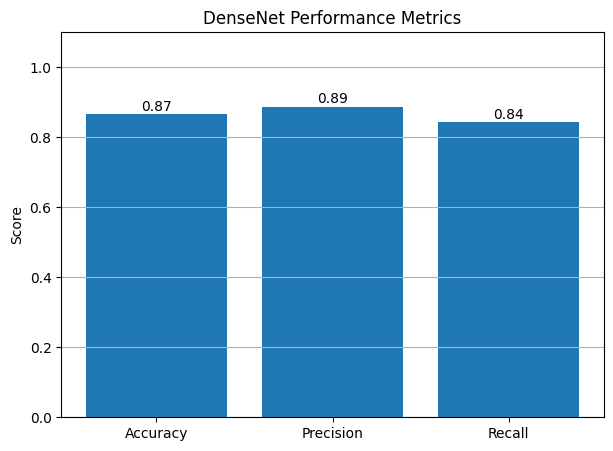

In [59]:
import matplotlib.pyplot as plt

# Metrics
metrics = ['Accuracy', 'Precision', 'Recall']
values = [0.8654, 0.8869, 0.8435]

# Plot
plt.figure(figsize=(7,5))

bars = plt.bar(metrics, values)

# Value labels
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.01,
        f'{yval:.2f}',
        ha='center'
    )

plt.ylim(0,1.1)

plt.ylabel('Score')

plt.title('DenseNet Performance Metrics')

plt.grid(axis='y')

plt.show()

In [62]:
print("Final Training Accuracy:",
      densenet_history.history['accuracy'][-1])

print("Final Validation Accuracy:",
      densenet_history.history['val_accuracy'][-1])

print("Final Training Precision:",
      densenet_history.history['precision'][-1])

print("Final Validation Precision:",
      densenet_history.history['val_precision'][-1])

Final Training Accuracy: 0.8520578145980835
Final Validation Accuracy: 0.7822222113609314
Final Training Precision: 0.8734423518180847
Final Validation Precision: 0.7993826866149902


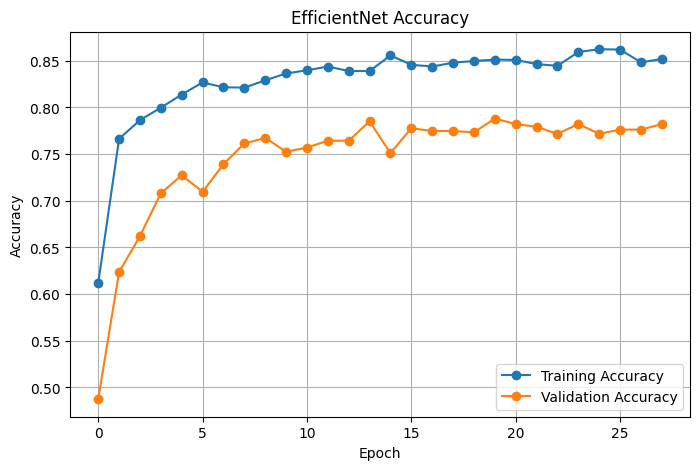

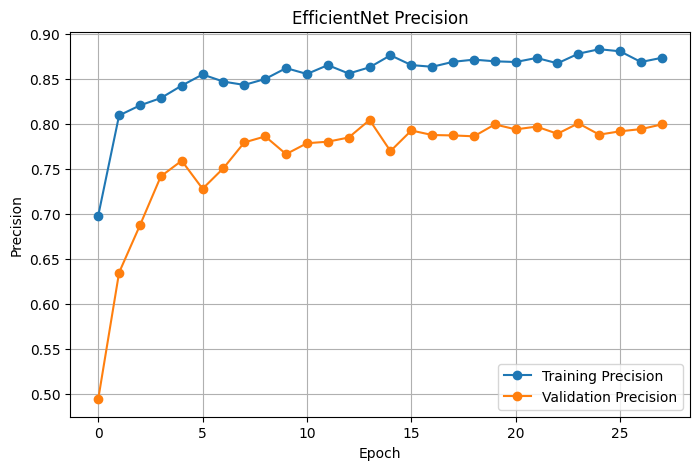

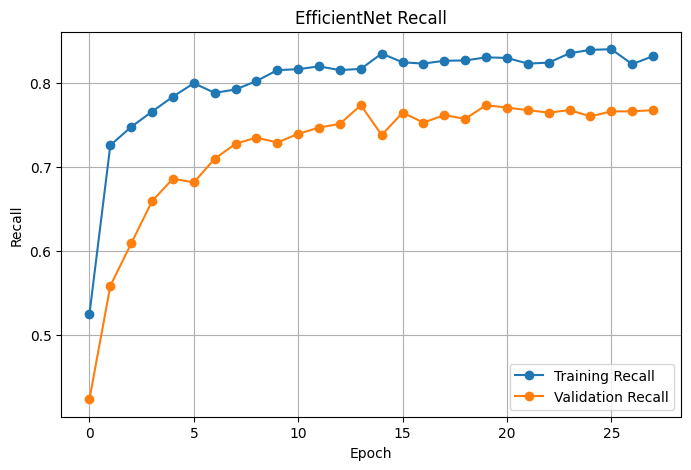

In [64]:
# =========================
# ACCURACY GRAPH
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    densenet_history.history['accuracy'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    densenet_history.history['val_accuracy'],
    marker='o',
    label='Validation Accuracy'
)

plt.title('EfficientNet Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

plt.grid(True)

plt.show()

# =========================
# PRECISION GRAPH
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    densenet_history.history['precision'],
    marker='o',
    label='Training Precision'
)

plt.plot(
    densenet_history.history['val_precision'],
    marker='o',
    label='Validation Precision'
)

plt.title('EfficientNet Precision')

plt.xlabel('Epoch')
plt.ylabel('Precision')

plt.legend()

plt.grid(True)

plt.show()

# =========================
# RECALL GRAPH
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    densenet_history.history['recall'],
    marker='o',
    label='Training Recall'
)

plt.plot(
    densenet_history.history['val_recall'],
    marker='o',
    label='Validation Recall'
)

plt.title('EfficientNet Recall')

plt.xlabel('Epoch')
plt.ylabel('Recall')

plt.legend()

plt.grid(True)

plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 872ms/step


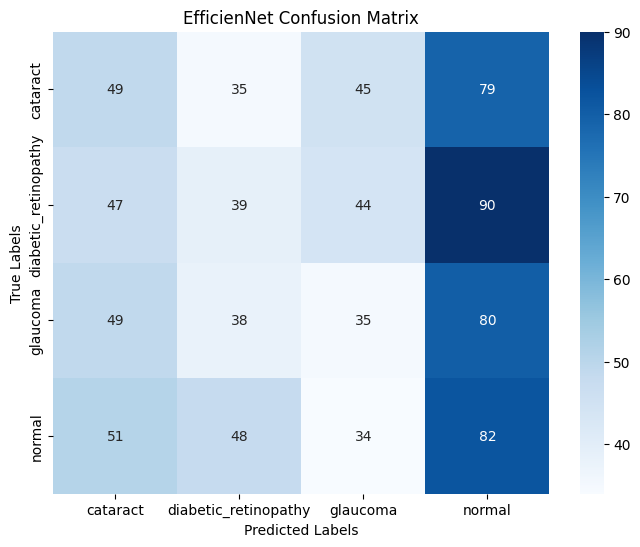


📌 Classification Report:

                      precision    recall  f1-score   support

            cataract       0.25      0.24      0.24       208
diabetic_retinopathy       0.24      0.18      0.21       220
            glaucoma       0.22      0.17      0.19       202
              normal       0.25      0.38      0.30       215

            accuracy                           0.24       845
           macro avg       0.24      0.24      0.24       845
        weighted avg       0.24      0.24      0.24       845



In [66]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# =========================
# RESET TEST GENERATOR
# =========================

test.reset()

# =========================
# PREDICTION
# =========================

y_pred = densenet_model.predict(test)

# Predicted class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# True class labels
y_true = test.classes

# Class names
class_labels = list(test.class_indices.keys())

# =========================
# CONFUSION MATRIX
# =========================

cm = confusion_matrix(y_true, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("EfficienNet Confusion Matrix")

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")

plt.show()

# =========================
# CLASSIFICATION REPORT
# =========================

print("\n📌 Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=class_labels
    )
)

In [47]:
Final_Report

[(np.float64(1.27),
  np.float64(1.28),
  np.float64(0.5),
  np.float64(0.46),
  np.float64(0.62),
  np.float64(0.68),
  np.float64(0.02),
  np.float64(0.02)),
 (np.float64(0.34),
  np.float64(0.38),
  np.float64(0.89),
  np.float64(0.87),
  np.float64(0.91),
  np.float64(0.89),
  np.float64(0.86),
  np.float64(0.83)),
 (np.float64(0.35),
  np.float64(0.54),
  np.float64(0.87),
  np.float64(0.79),
  np.float64(0.89),
  np.float64(0.81),
  np.float64(0.84),
  np.float64(0.77))]

In [68]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ===== Select Model & History =====
model = resnet50_model
history = resnet50_history
test_data = test

# ===== Prediction =====
y_pred = model.predict(test_data)

# predicted classes
y_pred_classes = np.argmax(y_pred, axis=1)

# true classes
y_true = test_data.classes

# ===== Metrics =====
accuracy = accuracy_score(y_true, y_pred_classes)

precision = precision_score(
    y_true,
    y_pred_classes,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred_classes,
    average='weighted'
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)

# ===== Classification Report =====
print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=list(test_data.class_indices.keys())
    )
)



# ===== Save Metrics Report =====
Model_accuracy = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],
    "Value": [accuracy, precision, recall]
})

print(Model_accuracy)

Model_accuracy.to_csv("Report.csv", index=False)

print("\nReport.csv saved successfully.")


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 862ms/step
Accuracy : 0.25443786982248523
Precision: 0.25542622495811274
Recall   : 0.25443786982248523

Classification Report:

                      precision    recall  f1-score   support

            cataract       0.28      0.16      0.21       208
diabetic_retinopathy       0.26      0.27      0.26       220
            glaucoma       0.24      0.15      0.19       202
              normal       0.25      0.42      0.32       215

            accuracy                           0.25       845
           macro avg       0.26      0.25      0.24       845
        weighted avg       0.26      0.25      0.24       845

      Metric     Value
0   Accuracy  0.254438
1  Precision  0.255426
2     Recall  0.254438

Report.csv saved successfully.


# Model Evaluation Summary For 3 Transfer Learning Models

###### Model_accuracy

In [3]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import itertools
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, utils


from tensorflow.keras.applications.efficientnet import EfficientNetB3, preprocess_input


from tensorflow.keras.preprocessing import image_dataset_from_directory


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, balanced_accuracy_score, confusion_matrix, roc_curve, auc


from sklearn.preprocessing import label_binarize

2026-05-12 19:26:55.475718: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778614015.677653    6342 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778614015.740945    6342 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778614016.207733    6342 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778614016.207777    6342 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778614016.207780    6342 computation_placer.cc:177] computation placer alr

In [5]:

print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

print("TensorFlow version:", tf.__version__)

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

Num GPUs Available:  1
TensorFlow version: 2.19.0


In [6]:
data_dir = "/kaggle/input/datasets/gunavenkatdoddi/eye-diseases-classification/dataset"
IMG_SIZE = (300, 300)
BATCH_SIZE = 64
SEED = 42

train_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels="inferred",
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb"
)

val_test_data = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels="inferred",
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb"
)


val_test_batches = tf.data.experimental.cardinality(val_test_data)

val_size = val_test_batches // 2
test_size = val_test_batches - val_size


validation_data = val_test_data.take(val_size)


testing_data = val_test_data.skip(val_size)


class_names = train_data.class_names

NUM_CLASSES = len(class_names)
print("Class names:", class_names)


print(f"Number of batches in the training data: {tf.data.experimental.cardinality(train_data)}")
print(f"Number of batches Validation data: {tf.data.experimental.cardinality(validation_data)}")
print(f"Number of batches Testing data: {tf.data.experimental.cardinality(testing_data)}")

Found 4217 files belonging to 4 classes.
Using 3374 files for training.


I0000 00:00:1778614038.283003    6342 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Found 4217 files belonging to 4 classes.
Using 843 files for validation.
Class names: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
Number of batches in the training data: 53
Number of batches Validation data: 7
Number of batches Testing data: 7


In [9]:
def preprocess_for_model(img):
    img = tf.cast(img, tf.float32)
    return preprocess_input(img)


def preprocess_for_display(img):
    img = tf.cast(img, tf.float32) / 255.0
    return img


train_dataset = train_data.map(lambda x, y: (preprocess_for_model(x), y))


val_dataset = validation_data.map(lambda x, y: (preprocess_for_model(x), y))


test_dataset = testing_data.map(lambda x, y: (preprocess_for_model(x), y))


display_dataset = train_data.map(lambda x, y: (preprocess_for_display(x), y))


print("Preprocessing completed.")
print("You now have: train_dataset, val_dataset, and test_dataset ready for the model")

Preprocessing completed.
You now have: train_dataset, val_dataset, and test_dataset ready for the model


In [10]:

def dataset_to_numpy(dataset):
    x_data, y_data = [], []
    print(f"Converting the dataset...")

    
    for images, labels in dataset:
        
        x_data.append(images.numpy())
        y_data.append(labels.numpy())

    print("Merging all batches...")
   
    x_data_np = np.concatenate(x_data, axis=0)
    
    y_data_np = np.concatenate(y_data, axis=0)

    return x_data_np, y_data_np

print("--- Starting the conversion process to NumPy ---")
print("\n[1/3] Converting training data...")
x_train, y_train = dataset_to_numpy(train_dataset)
print(f"-> Finished. Shape x_train: {x_train.shape}, y_train: {y_train.shape}")

print("\n[2/3] Converting validation data...")
# Mengonversi val_dataset ke NumPy array
x_val, y_val = dataset_to_numpy(val_dataset)
print(f"-> Finished. Shape x_val: {x_val.shape}, y_val: {y_val.shape}")

print("\n[3/3] Converting testing data...")
# Mengonversi test_dataset ke NumPy array
x_test, y_test = dataset_to_numpy(test_dataset)
print(f"-> Finished. Shape x_test: {x_test.shape}, y_test: {y_test.shape}")

print("\n--- Conversion finished ---")

--- Starting the conversion process to NumPy ---

[1/3] Converting training data...
Converting the dataset...
Merging all batches...
-> Finished. Shape x_train: (3374, 300, 300, 3), y_train: (3374,)

[2/3] Converting validation data...
Converting the dataset...
Merging all batches...
-> Finished. Shape x_val: (448, 300, 300, 3), y_val: (448,)

[3/3] Converting testing data...
Converting the dataset...
Merging all batches...
-> Finished. Shape x_test: (395, 300, 300, 3), y_test: (395,)

--- Conversion finished ---


In [11]:
print("\nFor Training Data:")
print("Shape of y_train before squeeze:", y_train.shape)
y_train_squeezed = np.squeeze(y_train)
print("Shape of y_train after squeeze:", y_train_squeezed.shape)
y_train_cat = utils.to_categorical(y_train_squeezed, NUM_CLASSES)
print("Shape of y_train after one-hot encoding:", y_train_cat.shape)


print("\nFor Validation Data:")
print("Shape of y_val before squeeze:", y_val.shape)
y_val_squeezed = np.squeeze(y_val)
print("Shape of y_val after squeeze:", y_val_squeezed.shape)
y_val_cat = utils.to_categorical(y_val_squeezed, NUM_CLASSES)
print("Shape of y_val after one-hot encoding:", y_val_cat.shape)


print("\nFor Testing Data:")
print("Shape of y_test before squeeze:", y_test.shape)
y_test_squeezed = np.squeeze(y_test)
print("Shape of y_test after squeeze:", y_test_squeezed.shape)
y_test_cat = utils.to_categorical(y_test_squeezed, NUM_CLASSES)
print("Shape of y_test after one-hot encoding:", y_test_cat.shape)

print("\n--- Process Completed ---")


For Training Data:
Shape of y_train before squeeze: (3374,)
Shape of y_train after squeeze: (3374,)
Shape of y_train after one-hot encoding: (3374, 4)

For Validation Data:
Shape of y_val before squeeze: (448,)
Shape of y_val after squeeze: (448,)
Shape of y_val after one-hot encoding: (448, 4)

For Testing Data:
Shape of y_test before squeeze: (395,)
Shape of y_test after squeeze: (395,)
Shape of y_test after one-hot encoding: (395, 4)

--- Process Completed ---


--- Preparing Data for Visualization ---

[1/3] Converting display_dataset (from training data)...
Converting the dataset...
Merging all batches...
-> Done. Shape x_display: (3374, 300, 300, 3), y_display: (3374,)

--- Sample Images from Training Set ---


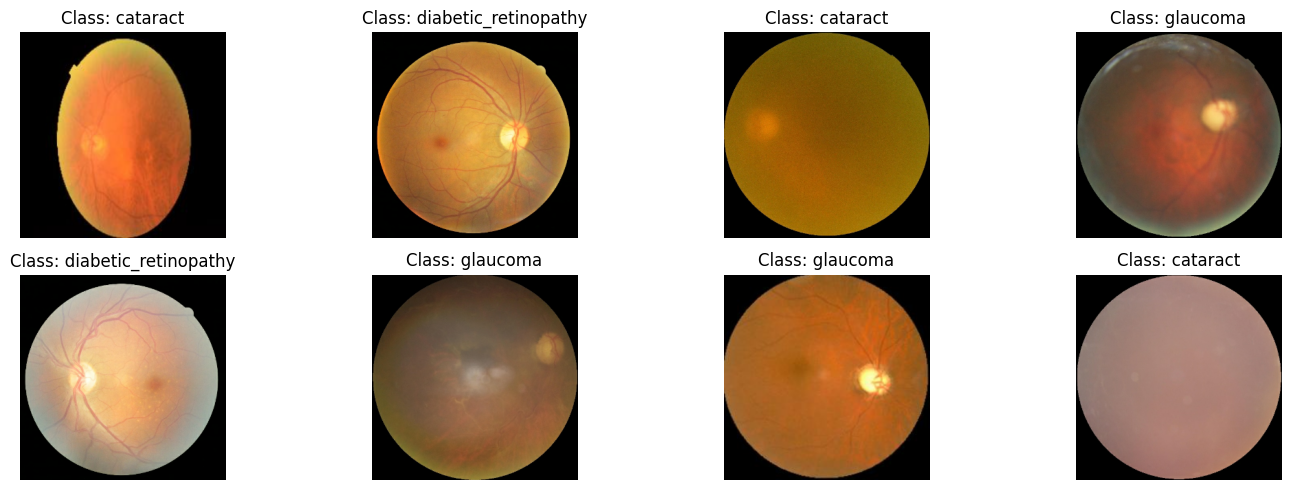


--- Sample Images from Validation Set ---
Converting the dataset...
Merging all batches...


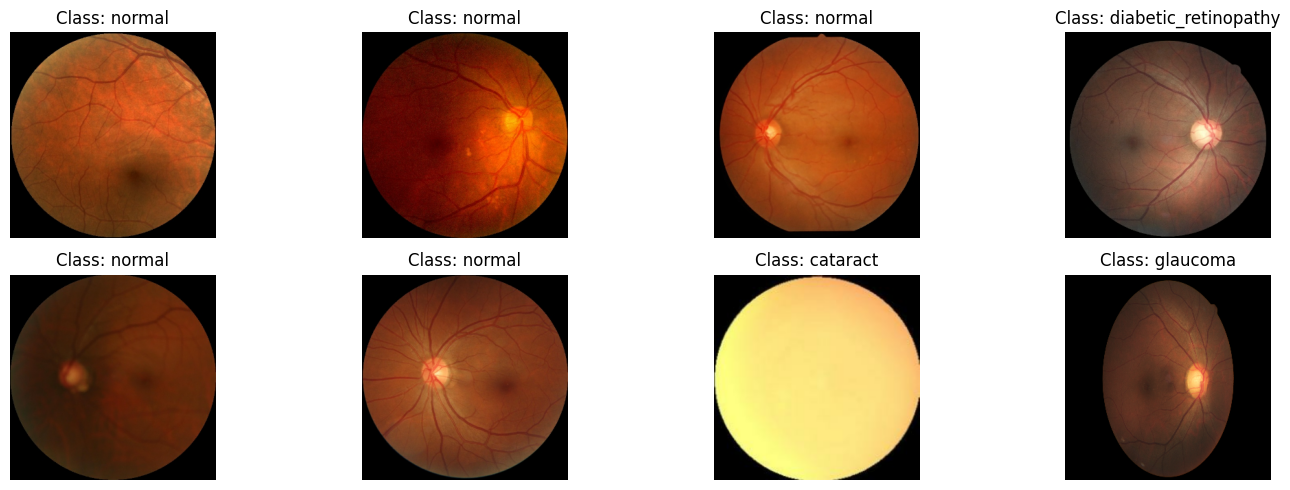


--- Sample Images from Testing Set ---
Converting the dataset...
Merging all batches...


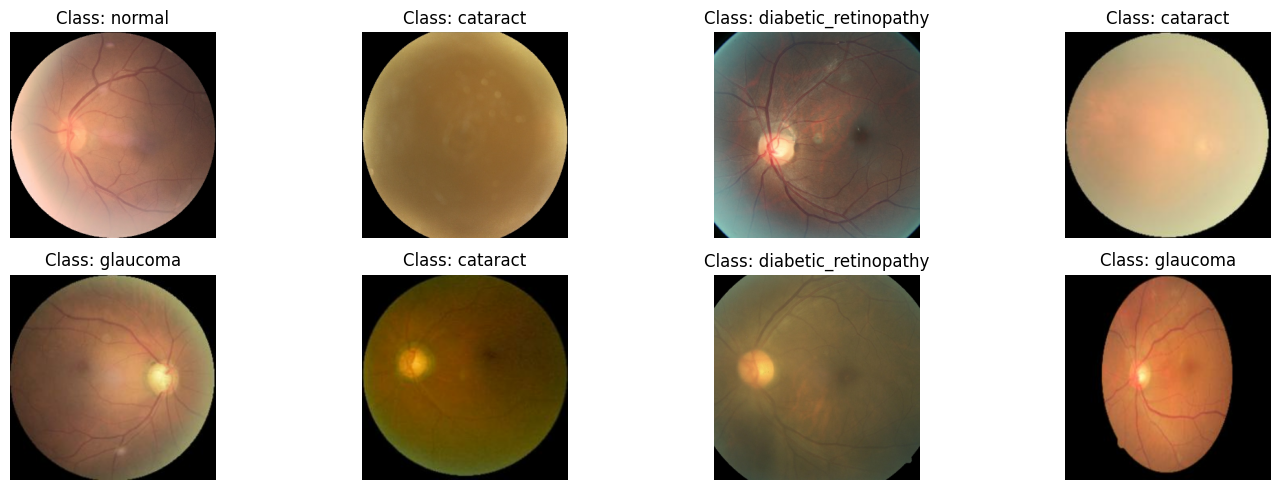

In [12]:
print("--- Preparing Data for Visualization ---")
print("\n[1/3] Converting display_dataset (from training data)...")
x_display, y_display = dataset_to_numpy(display_dataset)
print(f"-> Done. Shape x_display: {x_display.shape}, y_display: {y_display.shape}")


def display_images(images, labels, class_names_list, n=12, size=(15, 5)):
    # Ensuring n is not larger than available images
    n_display = min(n, len(images))
    indices = np.random.choice(len(images), n_display, replace=False)

    num_images_per_row = 4
    num_rows = (n_display + num_images_per_row - 1) // num_images_per_row

    fig, axes = plt.subplots(num_rows, num_images_per_row, figsize=size)
    if not isinstance(axes, np.ndarray): axes = np.array([axes])
    axes = axes.flatten()

    for i, idx in enumerate(indices):
        img, label_info = images[idx], labels[idx]

        # Logic to properly display image, even if values are not [0,1]
        if np.max(img) <= 1.0 and np.min(img) >= 0.0:
            img_disp = (img * 255).astype("uint8")
        else:
            img_disp = ((img - np.min(img)) / (np.max(img) - np.min(img)) * 255).astype("uint8")

        axes[i].imshow(img_disp)

        # Logic to display class name from label (both integer and one-hot)
        class_index = int(np.argmax(label_info)) if hasattr(label_info, "__len__") and len(label_info) > 1 else int(label_info)
        axes[i].set_title(f'Class: {class_names_list[class_index]}')
        axes[i].axis('off')

    # Hide unused axes
    for j in range(len(indices), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


# Display sample images from Training Set
print("\n--- Sample Images from Training Set ---")
display_images(x_display, y_display, class_names_list=class_names, n=8)

# Display sample images from Validation Set
print("\n--- Sample Images from Validation Set ---")
val_display_dataset = validation_data.map(lambda x, y: (preprocess_for_display(x), y))
x_val_display, y_val_display = dataset_to_numpy(val_display_dataset)
display_images(x_val_display, y_val_display, class_names_list=class_names, n=8)

# Display sample images from Testing Set
print("\n--- Sample Images from Testing Set ---")
test_display_dataset = testing_data.map(lambda x, y: (preprocess_for_display(x), y))
x_test_display, y_test_display = dataset_to_numpy(test_display_dataset)
display_images(x_test_display, y_test_display, class_names_list=class_names, n=8)

In [13]:
input_layer = layers.Input(shape=(300, 300, 3))


base_model = EfficientNetB3(weights='imagenet', include_top=False, input_tensor=input_layer)


base_model.trainable = False


x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
output_layer = layers.Dense(NUM_CLASSES, activation='softmax')(x)


model_efficientnetb3 = models.Model(inputs=input_layer, outputs=output_layer)


model_efficientnetb3.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 300, 300,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 300, 300,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 300, 300,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │        960 │ block1a_se_excit

 Total params: 11,178,035 (42.64 MB)

 Trainable params: 394,500 (1.50 MB)

 Non-trainable params: 10,783,535 (41.14 MB)

In [15]:
with tf.device('/GPU:0'):
    opt = optimizers.Adam(learning_rate=0.0001)
    model_efficientnetb3.compile(
        optimizer=opt,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("--- Starting Model Training ---")
  
    history = model_efficientnetb3.fit(
        x_train,
        y_train_cat,
        batch_size=32,
        epochs=100,
        validation_data=(x_val, y_val_cat),
        shuffle=True
    )

print("\nEvaluating the Model on Testing Data ---")

with tf.device('/GPU:0'):
    evaluation = model_efficientnetb3.evaluate(x_test, y_test_cat)
    print(f"EfficientNetB3 model evaluation results on testing data:")
    print(f"Test Loss: {evaluation[0]}")
    print(f"Test Accuracy: {evaluation[1]}")

--- Starting Model Training ---
Epoch 1/100


I0000 00:00:1778614213.035224    6397 service.cc:152] XLA service 0x7dadf8006000 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778614213.035273    6397 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1778614216.458523    6397 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1778614235.252846    6397 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


106/106 ━━━━━━━━━━━━━━━━━━━━ 82s 407ms/step - accuracy: 0.5162 - loss: 1.0866 - val_accuracy: 0.7924 - val_loss: 0.5843
Epoch 2/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.7532 - loss: 0.6412 - val_accuracy: 0.8348 - val_loss: 0.4754
Epoch 3/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.7952 - loss: 0.5427 - val_accuracy: 0.8504 - val_loss: 0.4385
Epoch 4/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8159 - loss: 0.4844 - val_accuracy: 0.8705 - val_loss: 0.3970
Epoch 5/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8334 - loss: 0.4503 - val_accuracy: 0.8817 - val_loss: 0.3712
Epoch 6/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8414 - loss: 0.4322 - val_accuracy: 0.8772 - val_loss: 0.3598
Epoch 7/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8428 - loss: 0.4104 - val_accuracy: 0.8884 - val_loss: 0.3426
Epoch 8/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8613 - loss: 0.3891 - val

In [16]:
weights_filename = 'model_efficientnetb3.weights.h5'


print(f"Saving weights to: {weights_filename}")


model_efficientnetb3.save_weights(weights_filename)


print("✓ Weights successfully saved.!")

Saving weights to: model_efficientnetb3.weights.h5
✓ Weights successfully saved.!


In [18]:
last_conv_layer_name = None
for layer in model_efficientnetb3.layers:
    if 'conv' in layer.name.lower() or 'top' in layer.name.lower():
        last_conv_layer_name = layer.name


print("Name of the last convolutional layer:", last_conv_layer_name)

Name of the last convolutional layer: top_activation



Accuracy : 0.9089
Precision (wgt) : 0.9098
Recall (wgt) : 0.9089
F1 Score (wgt) : 0.9093
Balanced Accuracy : 0.9067

Classification Report:
                      precision    recall  f1-score   support

            cataract       0.91      0.91      0.91        99
diabetic_retinopathy       1.00      0.98      0.99        98
            glaucoma       0.82      0.84      0.83        82
              normal       0.90      0.90      0.90       116

            accuracy                           0.91       395
           macro avg       0.91      0.91      0.91       395
        weighted avg       0.91      0.91      0.91       395



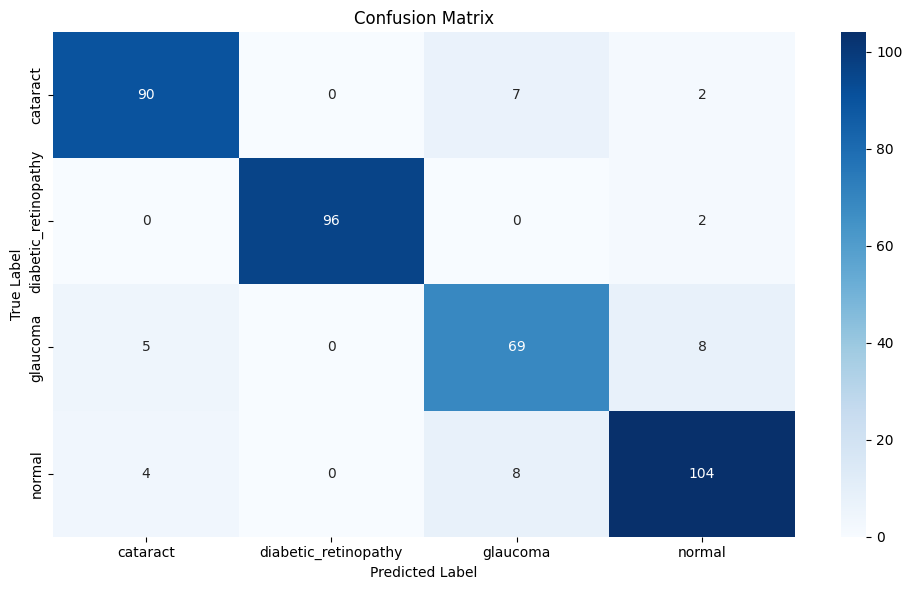

In [19]:
y_pred_probs = model_efficientnetb3.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

y_true_input = y_test_cat # Menggunakan y_test_cat yang sudah one-hot encoded
y_true_classes = np.argmax(y_true_input, axis=1).astype(int)

n_classes = y_pred_probs.shape[1]
assert y_pred_classes.shape[0] == y_true_classes.shape[0], "Jumlah sampel prediksi & ground-truth tidak sama."

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix
)

acc = accuracy_score(y_true_classes, y_pred_classes)
prec = precision_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
rec = recall_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
f1 = f1_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
bal_acc = balanced_accuracy_score(y_true_classes, y_pred_classes)

print(f"\nAccuracy : {acc:.4f}")
print(f"Precision (wgt) : {prec:.4f}")
print(f"Recall (wgt) : {rec:.4f}")
print(f"F1 Score (wgt) : {f1:.4f}")
print(f"Balanced Accuracy : {bal_acc:.4f}")
try:
    target_names = class_names if len(class_names) == n_classes else [f"class_{i}" for i in range(n_classes)]
except NameError:
    target_names = [f"class_{i}" for i in range(n_classes)]

print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=target_names, zero_division=0))

cm = confusion_matrix(y_true_classes, y_pred_classes, labels=np.arange(n_classes))

plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

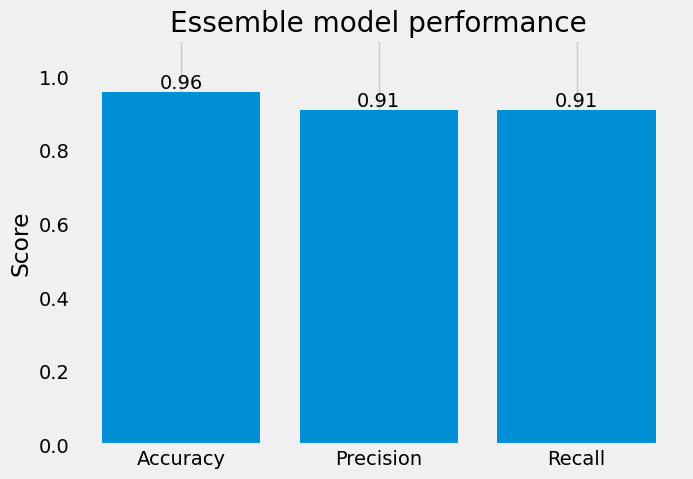

In [37]:
import matplotlib.pyplot as plt

# Metrics
metrics = ['Accuracy', 'Precision', 'Recall']
values = [0.9590 , 0.9098, 0.9089]

# Plot
plt.figure(figsize=(7,5))

bars = plt.bar(metrics, values)

# Value labels
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.01,
        f'{yval:.2f}',
        ha='center'
    )

plt.ylim(0,1.1)

plt.ylabel('Score')

plt.title('Essemble model performance')

plt.grid(axis='y')

plt.show()

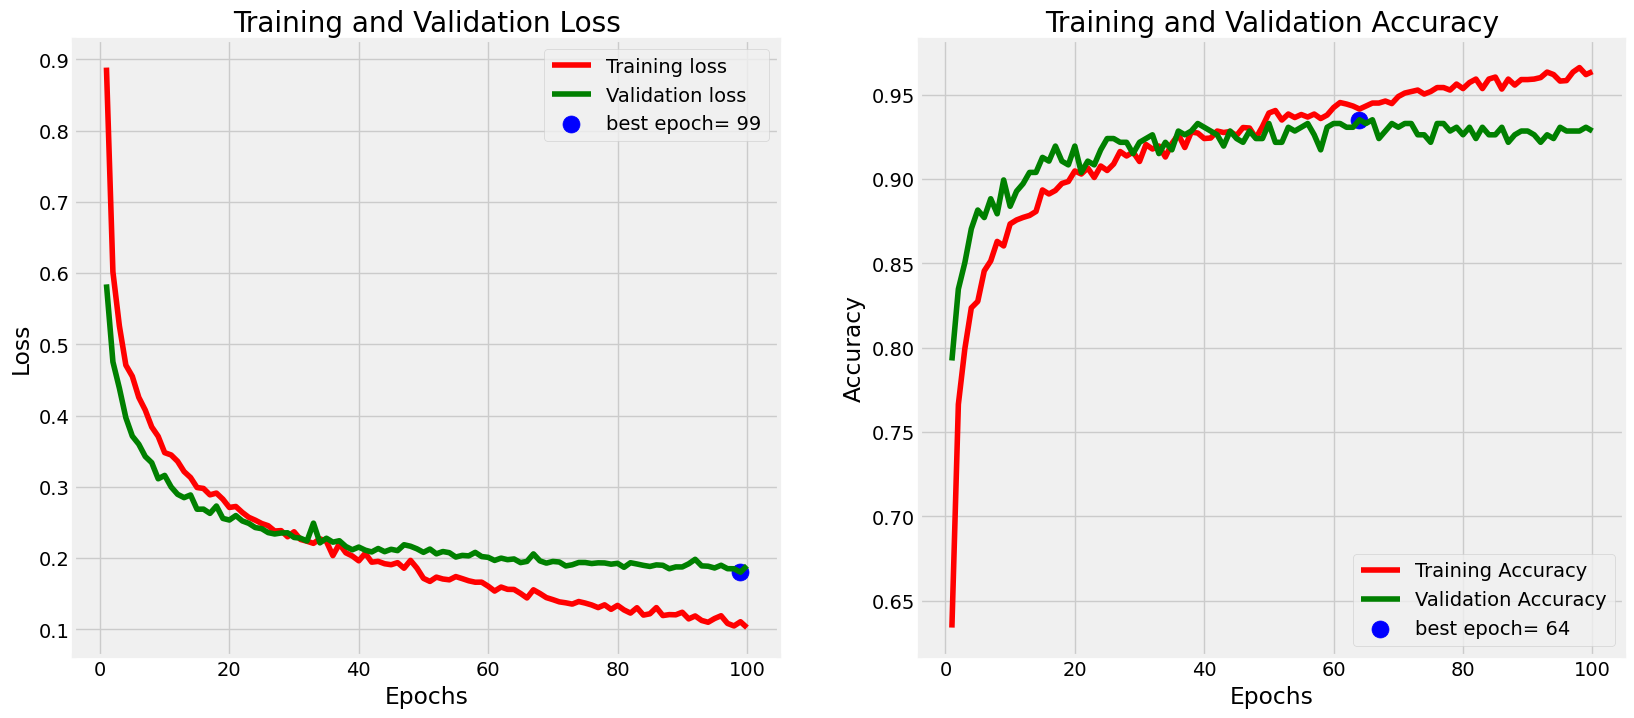

In [20]:
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

In [22]:
y_pred_prob = model_efficientnetb3.predict(x_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step


In [27]:
from sklearn.preprocessing import label_binarize

y_test_bin = y_test_cat  # already one-hot in your case

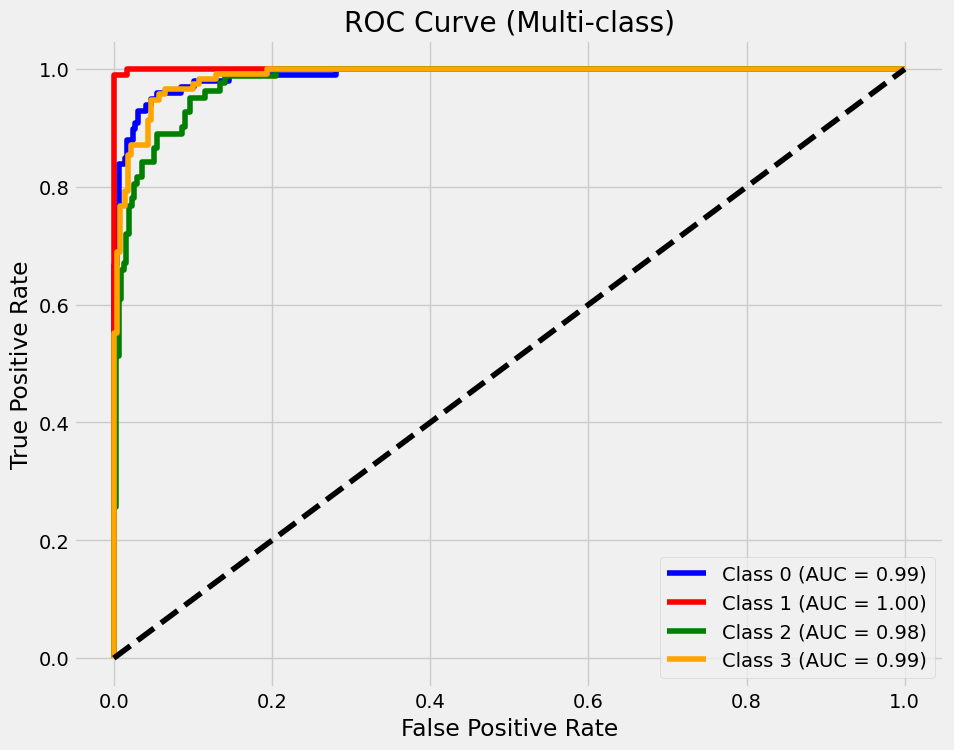

In [28]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle

n_classes = NUM_CLASSES

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green', 'orange', 'purple'])

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # random classifier line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Multi-class)')
plt.legend()
plt.show()

Model weights loaded successfully from model_efficientnetb3.weights.h5
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


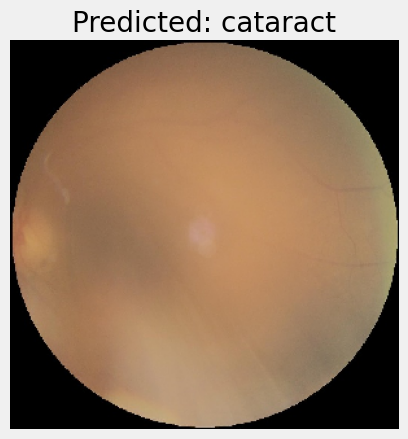

Prediction probabilities: [[9.9911946e-01 3.5133564e-06 4.4048374e-04 4.3656788e-04]]
Predicted class: cataract
Gambar dengan hasil prediksi telah disimpan di: predicted_image.jpg


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.efficientnet import preprocess_input


def predict_single_image(image_path, model, class_names, target_size=(300, 300)):
    img = load_img(image_path, target_size=target_size)
    
    img_array = img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)
    
    img_preprocessed = preprocess_input(img_batch.astype(np.float32))
    
    predictions = model.predict(img_preprocessed)
    
    predicted_index = np.argmax(predictions, axis=1)[0]
    predicted_class = class_names[predicted_index]
    
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class}")
    plt.axis("off")
    plt.show()
    
    print("Prediction probabilities:", predictions)
    print("Predicted class:", predicted_class)    
    output_path = "predicted_image.jpg"
    plt.imsave(output_path, np.array(img))
    print(f"Gambar dengan hasil prediksi telah disimpan di: {output_path}")

model_efficientnetb3.load_weights(weights_filename)
print(f"Model weights loaded successfully from {weights_filename}")

image_path = "/kaggle/input/datasets/gunavenkatdoddi/eye-diseases-classification/dataset/cataract/103_left.jpg"

predict_single_image(image_path, model_efficientnetb3, class_names)

In [53]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
import cv2
import matplotlib.pyplot as plt

In [54]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

In [55]:
last_conv_layer_name = 'top_activation'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


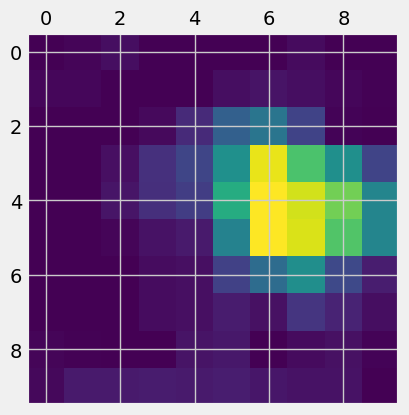

In [56]:
img_array = np.expand_dims(x_val[0], axis=0)


preds = model_efficientnetb3.predict(img_array)
pred_index = np.argmax(preds[0])


heatmap = make_gradcam_heatmap(img_array, model_efficientnetb3, last_conv_layer_name, pred_index)


plt.matshow(heatmap)
plt.show()

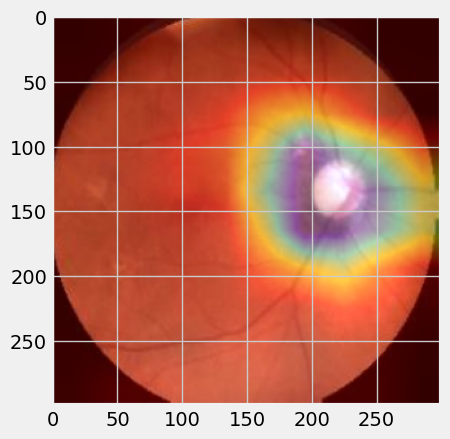

In [57]:
def overlay_heatmap_on_image(img, heatmap):
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = heatmap * 0.4 + img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    return superimposed_img

img = x_val[0]  # Contoh: mengambil gambar pertama dari data validasi
superimposed_img = overlay_heatmap_on_image(img, heatmap)

plt.imshow(superimposed_img)
plt.show()

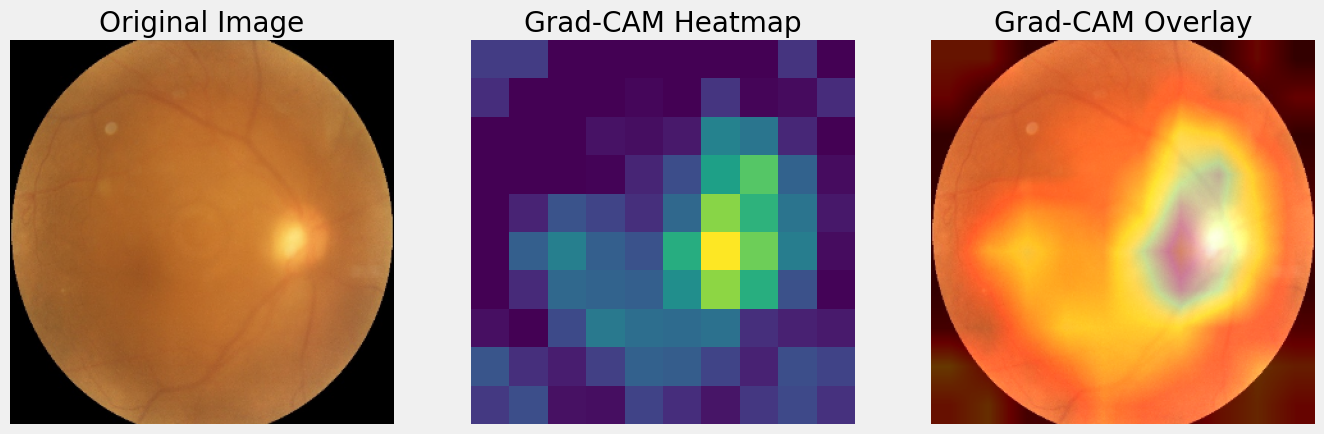

In [59]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

image_path = "/kaggle/input/datasets/gunavenkatdoddi/eye-diseases-classification/dataset/cataract/1084_right.jpg"
original_image = Image.open(image_path)

original_image = np.array(original_image)

if original_image.shape[-1] == 4:
    original_image = original_image[..., :3]

target_size = (300, 300)
original_image = cv2.resize(original_image, target_size)

heatmap = make_gradcam_heatmap(np.expand_dims(original_image, axis=0), model_efficientnetb3, last_conv_layer_name)

superimposed_img = overlay_heatmap_on_image(original_image, heatmap)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='viridis')
plt.title("Grad-CAM Heatmap")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(superimposed_img)
plt.title("Grad-CAM Overlay")
plt.axis('off')

plt.show()